<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QSVR_AnomalyDetection_Tscharke2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QSVR for semi-supervised anomaly detection under noise and adversarial attacks: Tscharke et al. (2026) step by step

**Paper.** K. Tscharke, M. Wendlinger, S. Issel, P. Debus (Fraunhofer AISEC), *Anomaly Detection with Quantum SVR in the NISQ Era: Limits of Robustness to Noise and Adversarial Attacks*, 2026 (DOI [10.5220/0014218600004052](https://doi.org/10.5220/0014218600004052), arXiv:2505.01012v3). The kernel model itself comes from Tscharke, Issel, Debus, *Semisupervised anomaly detection using support vector regression with quantum kernel*, IEEE QCE 2023.

**What this notebook does.** It rebuilds, on a CPU simulator, the three experiments of the paper:
1. a **quantum-kernel support vector regression (QSVR)** trained on *normal* samples only, which scores a sample by how badly it is reconstructed (semi-supervised anomaly detection, measured with the AUC);
2. the influence of **six quantum noise channels** (bit flip, phase flip, depolarizing, phase damping, amplitude damping, miscalibration) on the kernel circuit, simulated exactly with density matrices;
3. **white-box PGD adversarial attacks** (eps = 0.01 / 0.1 / 0.3), attacks transferred to the noisy models, and **adversarial training**.

The IBM hardware benchmark (27-qubit device at Ehningen) cannot be rerun here; the notebook instead runs the same kernel circuit on a **noisy fake IBM Falcon device** (calibration-based noise model) as an indicative stand-in and labels the hardware claims "cannot be checked".

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` (default in the config cell) uses 5 datasets, 1 seed and a coarser noise grid and takes about 10 minutes; `FAST_MODE = False` runs 10 datasets, 3 seeds and the paper's noise grid (see the config cell for the runtime of the committed run). Datasets are downloaded inside the notebook (OpenML, scikit-learn and Hugging Face mirrors); nothing needs to be uploaded.

**What you get at the end.** Real-data exploration plots, the drawn and verified kernel circuit (Qiskit and PennyLane), re-drawn analogues of Fig. 2, 3 and 4, analogues of Tables 3, 4 and 5, a classical baseline on identical inputs, and a claim-by-claim comparison with the paper ("reproduced" / "not reached" / "exceeded" / "cannot be checked").

## The paper in one page

**Problem.** Anomaly detection (AD) is a core IT-security task (intrusion, fraud, malicious traffic). Quantum kernel methods are a natural candidate, but NISQ hardware is noisy and ML models are open to adversarial examples. The authors ask: does a QSVR work on hardware, how robust is it to noise, and how robust is it to adversarial attacks?

**Model (Sect. 3.1).** A 5-qubit feature map `U(x)` = a layer of `RZ`, a layer of `RX` (one feature per qubit), then `IsingZZ` gates whose angle is the *product of two features*. The kernel is the probability of the all-zero state after `U(x_i)` followed by `U(x_j)^dagger` (inversion test): `K_ij = |<0|U(x_j)^dagger U(x_i)|0>|^2`. The QSVR is trained on normal data only to *reconstruct its input*; the reconstruction error is the continuous anomaly score; performance is the AUC with the anomaly class as positive.

**Data (Table 6).** Eleven datasets reduced to 5 dimensions by PCA: Credit-card fraud (CC), Census, Forest Cover Type (CoverT), DoH, EMNIST, Fashion-MNIST, KDD, MNIST, Mammography, URL and a constructed linearly separable Toy set (normal vs anomalous classes as in Table 6).

**Protocols.** Hardware: 30 normal training samples, 50 test samples with equal class ratio. Noise and attacks: 100 normal training samples, 100 balanced test samples (50 normal, 50 anomalous). Noise probabilities p in {0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5}; miscalibration over-rotation in 20 linear steps in [0, 2pi]. PGD: eps in {0.01, 0.1, 0.3}, 50 iterations, step alpha = eps/50; attacks are crafted on the noise-free model and then applied to the noisy models; adversarial training retrains on 100 adversarial copies of the training samples.

**Claims we can test here.** (i) noise-free AUC per dataset (Table 4, mean 0.75); (ii) robustness to depolarizing / phase damping / phase flip / bit flip, strong sensitivity to amplitude damping (dip at p=0.1-0.2, recovery to ~0.5) and periodic miscalibration dips at k*pi; (iii) PGD with eps=0.01 already lowers the AUC (DoH 0.67 -> 0.06), eps=0.3 drives it to ~0; (iv) noise does not make the attacked model better than random; (v) adversarial training does not reliably help (mean adversarial AUC 0.28 -> 0.31, clean AUC 0.75 -> 0.71, Tables 4 and 5); (vi) DoH kernel values under miscalibration differ by four orders of magnitude (Table 3). **Claims we cannot test:** everything measured on the real IBM device (average AUC 0.72 vs 0.76, hardware beats the simulator on CC and KDD).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Feature-map circuit | `RZ`, `RX` layer + `IsingZZ(x_i x_j)`; Fig. 1 not legible in the text | `RZ(a_i)`, `RX(a_i)` on every qubit, then `IsingZZ(a_i a_{i+1})` on a linear chain; angles `a = SCALE * x` with `SCALE = pi` (`# CHOICE`) |
| Kernel evaluation | inversion test, all-zero probability | same circuit, exact probability (no shot noise) in the main runs; 4096 shots in the fake-device run |
| QSVR regression target | reconstruct the input (from the 2023 paper, not available here) | five independent epsilon-SVRs with precomputed kernel, one per feature, target = the feature; score = squared reconstruction error (`# CHOICE`) |
| SVR hyper-parameters (`C`, epsilon) | not given | picked on 50 held-out *normal* validation samples (smallest reconstruction error); the angle scale is fixed (`# CHOICE`) |
| Pre-processing | PCA to 5 dimensions | `StandardScaler` -> `PCA(5)` -> `MinMaxScaler((0,1))`, all fitted on the normal training split only, test data clipped to [0,1] (`# CHOICE`; eps is measured in this unit cube) |
| Datasets | 11 (Table 6) | CC (OpenML 1597), Census (OpenML 1590), CoverT (scikit-learn), DoH (HF `c01dsnap/DoHTunnelAnalyzer`, Benign vs Malicious flows), EMNIST letters (HF), Fashion-MNIST and MNIST (HF), KDD = NSL-KDD KDDTrain+ (HF `Mireu-Lab/NSL-KDD`), Mammography (OpenML 310), Toy. **URL is not run**: the lexical-feature file of Mamun et al. is not publicly mirrored (`# CHOICE`) |
| Toy dataset | "constructed, linearly separable, class distance 0.4", file not public | synthetic by design: 5-D uniform cube, feature f0 in [0,0.3] (normal) vs [0.7,1] (anomalous). Reconstruction, not the authors' file |
| Class pools | full datasets | at most 2500 normal and 800 anomalous rows per dataset (random, seeded) to keep memory small (`# CHOICE`) |
| Sample sizes | 100 train / 100 test; 30 / 50 on hardware | same (`N_TRAIN`, `N_TEST`, `HW_TRAIN`, `HW_TEST`); plus 50 normal validation samples and 50 labelled anomalies used only by the *supervised* reference classifiers |
| Noise model | channel applied "to the quantum circuit" (PennyLane `default.mixed`) | exact density-matrix simulation; the channel acts on every wire after **every** gate (`# CHOICE`); phase damping uses lambda = p; miscalibration = extra `RX(p)` after every gate (`# CHOICE`) |
| PGD loss | untargeted, maximise the loss of Eq. 13 | anomaly score pushed **up** for normal and **down** for anomalous samples; `x` clipped to eps-ball and to [0,1]; no random start (`# CHOICE`) |
| Which eps for Tables 4/5 and the noisy attacks | eps = 0.1 for the noisy attacks; not stated for Tables 4/5 | both eps = 0.01 and eps = 0.1 are evaluated and shown (`# CHOICE`) |
| Adversarial training | 100 adversarial training samples | PGD copies of the 100 normal training samples replace the training set; the retrained model is attacked white-box again |
| Table 5 decision threshold | not given | 95th percentile of the scores of the 50 clean normal validation samples (`# CHOICE`) |
| Hardware | IBM Ehningen, default error mitigation | **not available**; noisy `FakeKolkataV2` (27-qubit Falcon) via Aer, layout [0,1,2,3,5], optimisation level 1, no mitigation |
| Reference models | QSVR, QAE, CSVR, CAE | QSVR; classical RBF-SVR reconstruction (CSVR); One-Class SVM and Isolation Forest as extra references; Random Forest and SVC(rbf) as *supervised* upper references. Quantum and classical autoencoders are not rebuilt |
| Seeds | deterministic, single run | `SEED = 42`; full run repeats the data split over three seeds, noise sweeps use the first seed |
| "reproduced" tolerance | n/a | +-0.05 AUC (the standard error of an AUC from 100 test samples is about 0.05) |

In [1]:
# Installs pinned to the versions this notebook was tested with. Colab already ships numpy, pandas, scikit-learn, matplotlib.
# A runtime restart may be requested after the first install on Colab; if so, restart and use Run all again.
import sys
IN_COLAB = "google.colab" in sys.modules
def _have_all():
    try:
        import qiskit, qiskit_aer, qiskit_ibm_runtime, pennylane, autograd, pylatexenc, huggingface_hub, PIL, pyarrow  # noqa
        return True
    except Exception:
        return False
if IN_COLAB or not _have_all():
    !pip -q install "qiskit==2.5.2" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" "pennylane==0.45.1" "autograd==1.8.0" pylatexenc huggingface_hub pyarrow pillow


In [2]:
# ---- Configuration: every tunable constant lives here ------------------------------------------
import math, numpy as np
SEED = 42
FAST_MODE = False              # True: about 7-10 minutes (5 datasets, 1 seed). False: 10 datasets, 3 seeds, the paper's noise grid (committed run: about 27 minutes on a shared laptop CPU)
DATA_DIR = "qc051_data"         # downloaded data are cached here
IBM_TOKEN = ""                  # reserved: real-hardware runs are NOT part of this notebook (needs an IBM Quantum account); left empty

N_QUBITS = 5                    # PCA dimension = number of qubits (paper)
N_TRAIN, N_VAL, N_TEST, N_SUP = 100, 50, 100, 50    # normal train / normal validation / balanced test / labelled anomalies for supervised references
PGD_STEPS = 50                  # paper Table 2: n = 50, alpha = eps / n
AT_EPS = [0.01, 0.1]            # attack strengths used for the Table 4/5 analogues (the paper does not state which eps those tables use)
SCALE_GRID = [math.pi]          # CHOICE: angle = pi * x with x in [0,1]; widen the grid (e.g. [0.5, 1, 2, math.pi]) to tune it on the validation split
C_GRID, EPS_SVR_GRID = [1.0, 10.0, 100.0], [0.01, 0.1]     # SVR hyper-parameters tuned on normal validation samples only
HW_SHOTS = 4096                 # shots per kernel entry in the fake-device run
CHANNELS_ALL = ["bit_flip", "phase_flip", "depolarizing", "phase_damping", "amplitude_damping"]
if FAST_MODE:
    DATASETS = ["Toy", "Mammo", "Census", "KDD", "DoH"]
    SEEDS = [SEED]
    NOISE_P = [0.05, 0.1, 0.3, 0.5]
    MISCAL = np.linspace(0, 2 * math.pi, 10)
    EPS_CURVE = [0.01, 0.1, 0.3]
    HW_DATASETS, HW_TRAIN, HW_TEST = ["KDD"], 20, 30
else:
    DATASETS = ["CC", "Census", "CoverT", "DoH", "EMNIST", "FMNIST", "KDD", "MNIST", "Mammo", "Toy"]
    SEEDS = [SEED, SEED + 1, SEED + 2]
    NOISE_P = [0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5]      # paper, Sect. 3.3
    MISCAL = np.linspace(0, 2 * math.pi, 20)              # paper: 20 linear steps between 0 and 2*pi
    EPS_CURVE = [0.01, 0.05, 0.1, 0.2, 0.3, 0.5]          # paper Fig. 4 goes up to 0.5
    HW_DATASETS, HW_TRAIN, HW_TEST = ["CC", "KDD", "DoH"], 30, 50   # hardware protocol of the paper (30 / 50)


In [3]:
# ---- Imports, versions, Hugging Face token, seeds ------------------------------------------------
import os, io, gc, time, warnings
import pandas as pd, matplotlib.pyplot as plt
import sklearn, qiskit, qiskit_aer, qiskit_ibm_runtime, pennylane as qml, autograd
from IPython.display import display
from importlib.metadata import version
warnings.filterwarnings("ignore", category=FutureWarning); warnings.filterwarnings("ignore", category=UserWarning)

HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN (only needed for gated datasets)
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
os.makedirs(DATA_DIR, exist_ok=True)
rng_global = np.random.default_rng(SEED); np.random.seed(SEED)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| qiskit", qiskit.__version__,
      "| qiskit-aer", qiskit_aer.__version__, "| qiskit-ibm-runtime", qiskit_ibm_runtime.__version__, "| pennylane", qml.__version__, "| autograd", version("autograd"))
print("FAST_MODE =", FAST_MODE, "| datasets:", DATASETS, "| seeds:", SEEDS)


numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | qiskit 2.5.2 | qiskit-aer 0.17.2 | qiskit-ibm-runtime 0.50.0 | pennylane 0.45.1 | autograd 1.8.0
FAST_MODE = False | datasets: ['CC', 'Census', 'CoverT', 'DoH', 'EMNIST', 'FMNIST', 'KDD', 'MNIST', 'Mammo', 'Toy'] | seeds: [42, 43, 44]


## 1. Data loaders

All ten datasets are public and downloaded here (no gated dataset is used, so no token is required; if a Hugging Face mirror ever becomes gated, add your own `HF_TOKEN` to Colab Secrets). Each loader returns two **pools**: rows that play the *normal* role and rows that play the *anomalous* role, together with the **original labels** (digit, letter, cover type, attack/benign, ...). The semi-supervised protocol only ever trains on the normal pool. A dataset that cannot be downloaded is reported as `BLOCKED` and skipped, never replaced by invented data.

In [4]:
# ---- Section 3: data loaders (each returns a dict with normal/anomalous pools) ----
import os, io, time
import numpy as np, pandas as pd

POOL_NORMAL, POOL_ANOM = 2500, 800        # CHOICE: cap each class pool so that RAM stays small

def _hf(repo, fname):
    from huggingface_hub import hf_hub_download
    return hf_hub_download(repo, fname, repo_type="dataset", local_dir=DATA_DIR,
                           token=HF_TOKEN or None)

def _openml(data_id):
    from sklearn.datasets import fetch_openml
    return fetch_openml(data_id=data_id, as_frame=True, data_home=DATA_DIR, parser="auto")

def _pack(name, Xn, yn, Xa, ya, feature_names, rng, desc, div=1.0):
    """Cap the pools (seeded), keep ORIGINAL labels next to the binary role."""
    def cap(X, y, n):
        if len(X) > n:
            idx = rng.choice(len(X), n, replace=False); X, y = X[idx], np.asarray(y)[idx]
        return X.astype(np.float64) / div, np.asarray(y)
    Xn, yn = cap(Xn, yn, POOL_NORMAL); Xa, ya = cap(Xa, ya, POOL_ANOM)
    return dict(name=name, Xn=Xn, yn=yn, Xa=Xa, ya=ya, features=list(feature_names), desc=desc)

def load_mammo(rng):
    d = _openml(310); X = d.data; y = d.target.astype(str)
    a = (y == "1").values
    return _pack("Mammo", X[~a].values, y[~a].values, X[a].values, y[a].values, X.columns, rng,
                 "OpenML 310 (Woods et al. 1993): '-1' = normal, '1' = malignant calcification")

def load_census(rng):
    d = _openml(1590); X = pd.get_dummies(d.data, dtype=float); y = d.target.astype(str)
    a = (y == ">50K").values
    return _pack("Census", X[~a].values, y[~a].values, X[a].values, y[a].values, X.columns, rng,
                 "OpenML 1590 adult/census income: <=50K normal, >50K anomalous; categoricals one-hot encoded")

def load_cc(rng):
    d = _openml(1597); X = d.data.astype(float); y = d.target.astype(str)
    a = (y == "1").values
    return _pack("CC", X[~a].values, y[~a].values, X[a].values, y[a].values, X.columns, rng,
                 "OpenML 1597 credit-card fraud (Pozzolo et al.): Class 0 normal, 1 fraud")

def load_covert(rng):
    from sklearn.datasets import fetch_covtype
    d = fetch_covtype(data_home=DATA_DIR, as_frame=True); X = d.data.astype(float); y = d.target.values
    a = y >= 5
    return _pack("CoverT", X[~a].values, y[~a], X[a].values, y[a], X.columns, rng,
                 "Forest cover type: classes 1-4 normal, 5-7 anomalous (as in the paper)")

def _hf_images(name, repo, files, is_normal, rng, desc, shift=0):
    """Image datasets from Hugging Face parquet files (PNG bytes). The class pools are capped BEFORE decoding (low memory)."""
    from PIL import Image
    df = pd.concat([pd.read_parquet(_hf(repo, f)) for f in files], ignore_index=True)
    y = df["label"].values - shift; nrm = is_normal(y)
    pick = lambda m, n: rng.choice(np.flatnonzero(m), min(n, int(m.sum())), replace=False)
    i_n, i_a = pick(nrm, POOL_NORMAL), pick(~nrm, POOL_ANOM)
    dec = lambda idx: np.stack([np.asarray(Image.open(io.BytesIO(df["image"].iloc[k]["bytes"])), dtype=np.uint8).ravel() for k in idx])
    out = _pack(name, dec(i_n), y[i_n], dec(i_a), y[i_a], [f"px{k}" for k in range(784)], rng, desc, div=255.)
    out["img_shape"] = (28, 28); return out

def load_mnist(rng):
    return _hf_images("MNIST", "ylecun/mnist", [f"mnist/{s}-00000-of-00001.parquet" for s in ("train", "test")],
                      lambda y: y <= 4, rng, "MNIST digits (HF ylecun/mnist): 0-4 normal, 5-9 anomalous")

def load_fmnist(rng):
    return _hf_images("FMNIST", "zalando-datasets/fashion_mnist",
                      [f"fashion_mnist/{s}-00000-of-00001.parquet" for s in ("train", "test")],
                      lambda y: y <= 4, rng, "Fashion-MNIST (HF zalando-datasets/fashion_mnist): classes 0-4 normal, 5-9 anomalous")

def load_emnist(rng):
    d = pd.read_parquet(_hf("tanganke/emnist_letters", "emnist-letters/test-00000-of-00001.parquet"), columns=["label"])
    shift = int(d["label"].min())                 # letters are coded 1..26 or 0..25
    return _hf_images("EMNIST", "tanganke/emnist_letters",
                      [f"emnist-letters/{s}-00000-of-00001.parquet" for s in ("train", "test")],
                      lambda y: y <= 12, rng, "EMNIST letters (HF tanganke/emnist_letters): A-M normal, N-Z anomalous", shift=shift)

def load_kdd(rng):
    df = pd.read_csv(_hf("Mireu-Lab/NSL-KDD", "train.csv"))
    y = df.pop("class").astype(str)
    X = pd.get_dummies(df, dtype=float); a = (y == "anomaly").values
    return _pack("KDD", X[~a].values, y[~a].values, X[a].values, y[a].values, X.columns, rng,
                 "NSL-KDD (Tavallaee et al. 2009) KDDTrain+: normal vs anomaly; protocol/service/flag one-hot")

def load_doh(rng):
    b = pd.read_csv(_hf("c01dsnap/DoHTunnelAnalyzer", "Benign-DoH.csv"))
    m = pd.read_csv(_hf("c01dsnap/DoHTunnelAnalyzer", "Malicious-DoH.csv"))
    drop = ["SourceIP", "DestinationIP", "SourcePort", "DestinationPort", "TimeStamp"]
    lab = lambda df: df.pop(df.columns[-1]).astype(str).values
    yb, ym = lab(b), lab(m); b = b.drop(columns=drop); m = m.drop(columns=drop)
    b = b.apply(pd.to_numeric, errors="coerce"); m = m.apply(pd.to_numeric, errors="coerce")
    ok_b = np.isfinite(b.values).all(1); ok_m = np.isfinite(m.values).all(1)
    return _pack("DoH", b.values[ok_b], yb[ok_b], m.values[ok_m], ym[ok_m], b.columns, rng,
                 "CIC-DoHBrw-2020 Layer-2 flows (HF mirror c01dsnap/DoHTunnelAnalyzer): Benign vs Malicious")

def load_toy(rng):
    # Paper: "constructed to be linearly separable with a separation distance of 0.4". The authors' file is not public,
    # so this is a transparent reconstruction (synthetic by design, not real data). # CHOICE
    n = POOL_NORMAL
    Xn = rng.uniform(0, 1, (n, 5)); Xn[:, 0] = rng.uniform(0.0, 0.3, n)
    Xa = rng.uniform(0, 1, (POOL_ANOM, 5)); Xa[:, 0] = rng.uniform(0.7, 1.0, POOL_ANOM)
    return _pack("Toy", Xn, np.array(["Normal"] * n), Xa, np.array(["Anomalous"] * POOL_ANOM),
                 [f"f{i}" for i in range(5)], rng,
                 "Synthetic 5-D toy set, linearly separable along f0 with gap 0.4 (reconstruction of the paper's Toy)")

LOADERS = dict(CC=load_cc, Census=load_census, CoverT=load_covert, DoH=load_doh, EMNIST=load_emnist,
               FMNIST=load_fmnist, KDD=load_kdd, MNIST=load_mnist, Mammo=load_mammo, Toy=load_toy)


## 2. The quantum building blocks: exact kernel, noisy kernel, QSVR, PGD

Everything numerical is in four cells so that it can be checked against Qiskit and PennyLane in the circuit section below.

* **Noise-free kernel.** The state `U(a)|0>` of the five-qubit feature map has a closed form (product state of `RX RZ` rotations times a diagonal `IsingZZ` phase), so the kernel matrix is `|<phi(x_i)|phi(x_j)>|^2` computed with plain linear algebra. It is also differentiable with `autograd`, which gives exact PGD gradients for all samples at once.
* **Noisy kernel.** The kernel of the noisy circuit is `Tr[ P0 * E_{U(x_j)^dagger}( E_{U(x_i)}(|0><0|) ) ]`. The forward half depends only on `x_i` and the inverse half only on `x_j`, so the inverse half is simulated in the Heisenberg picture (adjoint channels applied to the projector `|0..0><0..0|`). That costs `O(n)` density-matrix simulations instead of `O(n^2)` and is *exact* (no shot noise), like PennyLane's `default.mixed` in the paper. The cell below is validated against PennyLane `default.mixed` in the circuit section.
* **QSVR.** One epsilon-SVR with precomputed kernel per input feature; the anomaly score is the squared reconstruction error. All fitting uses normal training samples only.

In [5]:
# ---- Quantum kernel simulator: noiseless statevector + exact noisy density matrices -------------
# Feature map U(a) on 5 qubits (a = SCALE * x are the encoded angles):
#   layer of RZ(a_i), layer of RX(a_i), then IsingZZ(a_i * a_{i+1}) on neighbouring qubits (linear chain)  # CHOICE (Fig. 1 not readable)
# Kernel: K(x_i, x_j) = | <0| U(x_j)^dagger U(x_i) |0> |^2  = probability of the all-zero state.
import numpy as np
import autograd, autograd.numpy as anp

NQ = N_QUBITS
BITS = (np.arange(2 ** NQ)[:, None] >> (NQ - 1 - np.arange(NQ))) & 1      # qubit 0 = most significant bit
ZS = 1 - 2 * BITS                                                          # (32, 5) eigenvalues of Z_i
PAIRS = [(i, i + 1) for i in range(NQ - 1)]                                # CHOICE: nearest-neighbour ZZ chain

# ---------- noiseless, differentiable statevector (used for the kernel, SVR and PGD gradients) -----
def state_ag(a):
    """a: (NQ,) encoded angles -> complex statevector (32,), autograd-differentiable."""
    q0 = anp.exp(-0.5j * a) * anp.cos(a / 2)                 # <0| RX(a) RZ(a) |0>
    q1 = -1j * anp.exp(-0.5j * a) * anp.sin(a / 2)           # <1| RX(a) RZ(a) |0>
    s = anp.array([q0[0], q1[0]])
    for i in range(1, NQ):
        s = anp.outer(s, anp.array([q0[i], q1[i]])).ravel()
    theta = 0.0
    for (i, j) in PAIRS:
        theta = theta - 0.5 * a[i] * a[j] * ZS[:, i] * ZS[:, j]
    return s * anp.exp(1j * theta)

def states_ag(A):
    """Batched, autograd-differentiable version of state_ag: A (B, NQ) -> (B, 32) complex."""
    q0 = anp.exp(-0.5j * A) * anp.cos(A / 2); q1 = -1j * anp.exp(-0.5j * A) * anp.sin(A / 2)
    s = anp.stack([q0[:, 0], q1[:, 0]], 1)
    for i in range(1, NQ):
        s = anp.reshape(s[:, :, None] * anp.stack([q0[:, i], q1[:, i]], 1)[:, None, :], (A.shape[0], -1))
    theta = 0.0
    for (i, j) in PAIRS:
        theta = theta - 0.5 * (A[:, i] * A[:, j])[:, None] * (ZS[:, i] * ZS[:, j])[None, :]
    return s * anp.exp(1j * theta)

def states_np(A):
    """A: (B, NQ) encoded angles -> (B, 32) complex states (vectorised, plain numpy)."""
    A = np.atleast_2d(A)
    q0 = np.exp(-0.5j * A) * np.cos(A / 2); q1 = -1j * np.exp(-0.5j * A) * np.sin(A / 2)
    s = np.stack([q0[:, 0], q1[:, 0]], 1)
    for i in range(1, NQ):
        s = (s[:, :, None] * np.stack([q0[:, i], q1[:, i]], 1)[:, None, :]).reshape(len(A), -1)
    theta = np.zeros((len(A), 2 ** NQ))
    for (i, j) in PAIRS:
        theta -= 0.5 * (A[:, i] * A[:, j])[:, None] * (ZS[:, i] * ZS[:, j])[None, :]
    return s * np.exp(1j * theta)

def kernel_noiseless(Xa, Xb, scale):
    """K[i, j] = |<phi(Xa_i)|phi(Xb_j)>|^2 (exact)."""
    Sa, Sb = states_np(scale * Xa), states_np(scale * Xb)
    return np.abs(Sa.conj() @ Sb.T) ** 2

# ---------- exact noisy simulation with density matrices ---------------------------------------
I2 = np.eye(2, dtype=complex); PX = np.array([[0, 1], [1, 0]], complex)
PY = np.array([[0, -1j], [1j, 0]]); PZ = np.diag([1, -1]).astype(complex)

def kraus(channel, p):
    """Single-qubit Kraus operators of the paper's channels (Sect. 2.2). 'phase_damping' uses lambda = p."""
    if channel == "bit_flip":       return [np.sqrt(1 - p) * I2, np.sqrt(p) * PX]
    if channel == "phase_flip":     return [np.sqrt(1 - p) * I2, np.sqrt(p) * PZ]
    if channel == "depolarizing":   return [np.sqrt(1 - p) * I2] + [np.sqrt(p / 3) * P for P in (PX, PY, PZ)]
    if channel == "phase_damping":  return [np.diag([1, np.sqrt(1 - p)]).astype(complex), np.diag([0, np.sqrt(p)]).astype(complex)]
    if channel == "amplitude_damping":
        return [np.array([[1, 0], [0, np.sqrt(1 - p)]], complex), np.array([[0, np.sqrt(p)], [0, 0]], complex)]
    if channel == "miscalibration": # coherent over-rotation RX(p) after every gate  # CHOICE (paper: fixed-angle rotation)
        c, s = np.cos(p / 2), np.sin(p / 2); return [np.array([[c, -1j * s], [-1j * s, c]])]
    raise ValueError(channel)

def _rot(kind, ang):
    c, s = np.cos(ang / 2), np.sin(ang / 2); U = np.zeros((len(ang), 2, 2), complex)
    if kind == "rz": U[:, 0, 0] = c - 1j * s; U[:, 1, 1] = c + 1j * s
    else:            U[:, 0, 0] = c; U[:, 1, 1] = c; U[:, 0, 1] = -1j * s; U[:, 1, 0] = -1j * s
    return U

def _sop(Ms, adjoint=False):
    """Super-operator S[p,q,r,s] = sum_k M[p,r] conj(M[q,s]) of a channel with Kraus operators Ms (or of the Heisenberg-picture
    adjoint channel when adjoint=True: M -> M^dagger).  Works for stacks of unitaries (B,2,2) too."""
    out = 0
    for M in Ms:
        if adjoint: M = np.conj(np.swapaxes(M, -1, -2))
        out = out + (np.einsum("...pr,...qs->...pqrs", M, np.conj(M)))
    return out

def _apply_S(rho, S, q):
    """rho (B,32,32) -> channel S acting on qubit q (row axis r and column axis s of that qubit)."""
    B = rho.shape[0]; pre, post = 2 ** q, 2 ** (NQ - 1 - q)
    r7 = rho.reshape(B, pre, 2, post, pre, 2, post)
    sub = "pqrs,barmcsn->bapmcqn" if S.ndim == 4 else "bpqrs,barmcsn->bapmcqn"
    return np.einsum(sub, S, r7, optimize=True).reshape(B, 2 ** NQ, 2 ** NQ)
def circuit_gates(A, inverse=False):
    """Gate list of U(A) (or of U(A)^dagger = reversed gates, negated angles). A: (B, NQ)."""
    g = [("rz", (q,), A[:, q]) for q in range(NQ)] + [("rx", (q,), A[:, q]) for q in range(NQ)] \
        + [("zz", (i, j), A[:, i] * A[:, j]) for (i, j) in PAIRS]
    return [(k, qs, -ang) for (k, qs, ang) in g[::-1]] if inverse else g

def _zz_diag(rho, ang, qs, adjoint=False):
    sign = -1 if adjoint else 1                               # IsingZZ is diagonal: rho -> D rho D^dagger
    D = np.exp(-0.5j * sign * ang[:, None] * (ZS[:, qs[0]] * ZS[:, qs[1]])[None, :])
    return rho * D[:, :, None] * np.conj(D)[:, None, :]

def run_forward(gates, channel, p):
    B = len(gates[0][2]); rho = np.zeros((B, 2 ** NQ, 2 ** NQ), complex); rho[:, 0, 0] = 1
    SN = None if channel is None else _sop(kraus(channel, p))
    for kind, qs, ang in gates:
        if kind == "zz":
            rho = _zz_diag(rho, ang, qs)
            if SN is not None:
                for q in qs: rho = _apply_S(rho, SN, q)
        else:                                                # gate and noise merged into one super-operator
            SG = _sop([_rot(kind, ang)])
            rho = _apply_S(rho, SG if SN is None else np.einsum("pqac,bacrs->bpqrs", SN, SG), qs[0])
    return rho

def run_heisenberg(gates, channel, p):
    """Adjoint of the whole noisy circuit applied to the projector |0..0><0..0| (reverse gate order)."""
    B = len(gates[0][2]); O = np.zeros((B, 2 ** NQ, 2 ** NQ), complex); O[:, 0, 0] = 1
    SN = None if channel is None else _sop(kraus(channel, p), adjoint=True)
    for kind, qs, ang in gates[::-1]:
        if kind == "zz":
            if SN is not None:
                for q in qs: O = _apply_S(O, SN, q)
            O = _zz_diag(O, ang, qs, adjoint=True)
        else:
            SG = _sop([_rot(kind, ang)], adjoint=True)
            O = _apply_S(O, SG if SN is None else np.einsum("bpqac,acrs->bpqrs", SG, SN), qs[0])
    return O
def kernel_noisy(Xa, Xb, scale, channel, p, chunk=200):
    """K[i,j] = P(all zeros) after noisy U(Xb_j)^dagger U(Xa_i), noise channel after every gate on every touched qubit."""
    Ra = np.concatenate([run_forward(circuit_gates(scale * Xa[s:s + chunk]), channel, p)
                         for s in range(0, len(Xa), chunk)])
    K = np.empty((len(Xa), len(Xb)))
    for s in range(0, len(Xb), chunk):
        Ob = run_heisenberg(circuit_gates(scale * Xb[s:s + chunk], inverse=True), channel, p)
        K[:, s:s + chunk] = np.einsum("jab,iba->ij", Ob, Ra).real
    return K


In [6]:
# ---- Preprocessing, QSVR (semi-supervised anomaly detection), PGD attack ----------------------
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVR
from sklearn.metrics import roc_auc_score

def make_split(ds, seed, n_train=None, n_val=None, n_test=None):
    """Semi-supervised split: the training set holds NORMAL samples only. Every transform is fitted on it only."""
    rng = np.random.default_rng(seed)
    pn, pa = rng.permutation(len(ds["Xn"])), rng.permutation(len(ds["Xa"]))
    nt, nv = n_train or N_TRAIN, n_val or N_VAL; h = (n_test or N_TEST) // 2
    i_tr, i_va = pn[:nt], pn[nt:nt + nv]
    i_te = pn[nt + nv:nt + nv + h]
    j_te, j_sup = pa[:h], pa[h:h + N_SUP]
    scaler = StandardScaler().fit(ds["Xn"][i_tr])
    pca = PCA(n_components=N_QUBITS, random_state=SEED).fit(scaler.transform(ds["Xn"][i_tr]))
    raw = lambda X: pca.transform(scaler.transform(X))
    mm = MinMaxScaler((0, 1)).fit(raw(ds["Xn"][i_tr]))
    prep = lambda X: np.clip(mm.transform(raw(X)), 0, 1)              # CHOICE: normalised input set S = [0,1]^5
    sp = dict(Xtr=prep(ds["Xn"][i_tr]), Xva=prep(ds["Xn"][i_va]),
              Xte=prep(np.vstack([ds["Xn"][i_te], ds["Xa"][j_te]])),
              yte=np.r_[np.zeros(h, int), np.ones(h, int)],
              Xsup=prep(ds["Xa"][j_sup]),
              raw_tr=raw(ds["Xn"][i_tr]), raw_te=raw(np.vstack([ds["Xn"][i_te], ds["Xa"][j_te]])),
              lab_tr=ds["yn"][i_tr], lab_te=np.r_[ds["yn"][i_te], ds["ya"][j_te]],
              pca_var=pca.explained_variance_ratio_)
    return sp

def fit_qsvr(K_train, X_train, C, eps):
    """One SVR per output feature (reconstruct x from x). Returns dense dual weights (n,5) and intercepts (5,)."""
    n = len(X_train); Alpha = np.zeros((n, N_QUBITS)); b = np.zeros(N_QUBITS)
    for k in range(N_QUBITS):
        m = SVR(kernel="precomputed", C=C, epsilon=eps).fit(K_train, X_train[:, k])
        Alpha[m.support_, k] = m.dual_coef_[0]; b[k] = m.intercept_[0]
    return Alpha, b

def anomaly_score(K_cross, X, Alpha, b):
    """Reconstruction error ||x - f(x)||^2; K_cross[i, j] = kernel(train_i, sample_j)."""
    return ((X - (K_cross.T @ Alpha + b)) ** 2).sum(1)

def auc(y, s):
    return float(roc_auc_score(y, s))

def select_hparams(sp):
    """Tune angle scale, C and epsilon on held-out NORMAL validation samples only (reconstruction MSE)."""
    best = None
    for sc in SCALE_GRID:
        Ktr = kernel_noiseless(sp["Xtr"], sp["Xtr"], sc); Kva = kernel_noiseless(sp["Xtr"], sp["Xva"], sc)
        for C in C_GRID:
            for eps in EPS_SVR_GRID:
                Alpha, b = fit_qsvr(Ktr, sp["Xtr"], C, eps)
                mse = anomaly_score(Kva, sp["Xva"], Alpha, b).mean()
                if best is None or mse < best[0]: best = (mse, sc, C, eps)
    return dict(scale=best[1], C=best[2], eps=best[3], val_mse=best[0])

def train_qsvr(sp, hp, X_train=None, channel=None, p=0.0):
    """Gram matrix (noiseless or noisy), SVR fit. Returns a model dict."""
    Xt = sp["Xtr"] if X_train is None else X_train
    kf = (lambda A, B: kernel_noiseless(A, B, hp["scale"])) if channel is None else \
         (lambda A, B: kernel_noisy(A, B, hp["scale"], channel, p))
    Ktr = kf(Xt, Xt); Ktr = 0.5 * (Ktr + Ktr.T)
    Alpha, b = fit_qsvr(Ktr, Xt, hp["C"], hp["eps"])
    return dict(Xt=Xt, Alpha=Alpha, b=b, kf=kf, hp=hp)

def score_with(model, X):
    return anomaly_score(model["kf"](model["Xt"], X), X, model["Alpha"], model["b"])

# ---------- PGD attack on the noiseless QSVR (white-box, autograd through the statevector) --------
def make_score_grad(model):
    """Batched anomaly score of the noiseless QSVR and its gradient with respect to the inputs (autograd)."""
    sc, Alpha, b = model["hp"]["scale"], model["Alpha"], model["b"]
    Tc = states_np(sc * model["Xt"]).conj()
    def total_score(X):                                          # samples are independent -> grad of the sum = per-sample grads
        ov = anp.dot(states_ag(sc * X), Tc.T); k = anp.real(ov) ** 2 + anp.imag(ov) ** 2
        return anp.sum((X - (anp.dot(k, Alpha) + b)) ** 2)
    return total_score, autograd.grad(total_score)

def pgd(model, X, y, eps, steps=None):
    """Untargeted L_inf PGD (Eq. 14, Table 2: n = 50 iterations, alpha = eps / n). Loss = anomaly score: normal samples
    (y=0) are pushed UP, anomalies (y=1) DOWN.  # CHOICE: the paper does not spell out the loss of the regression model."""
    steps = steps or PGD_STEPS; alpha = eps / steps
    _, g = make_score_grad(model); sgn = np.where(np.asarray(y) == 0, 1.0, -1.0)[:, None]; x = X.copy()
    for _ in range(steps):
        x = x + sgn * alpha * np.sign(g(x))
        x = np.clip(np.clip(x, X - eps, X + eps), 0, 1)
    return x


In [7]:
# ---- Experiments: noiseless benchmark, noise sweep, attacks, adversarial training, baselines ---
import pandas as pd
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.svm import SVC, OneClassSVM

CHANNELS = ["bit_flip", "phase_flip", "depolarizing", "phase_damping", "amplitude_damping"]

def noisy_aucs(sp, hp, channel, p, sets, y):
    """Train the noisy QSVR on sp['Xtr'] and return the AUC of every sample set in `sets` (dict name -> X).
    The forward half U(x_train) is simulated once, the inverse half U^dagger(x_other) in the Heisenberg picture."""
    sc, Xt = hp["scale"], sp["Xtr"]; n = len(Xt)
    Ra = run_forward(circuit_gates(sc * Xt), channel, p)
    allX = np.vstack([Xt] + list(sets.values())); K = np.empty((n, len(allX)))
    for s in range(0, len(allX), 200):
        O = run_heisenberg(circuit_gates(sc * allX[s:s + 200], inverse=True), channel, p)
        K[:, s:s + 200] = np.einsum("jab,iba->ij", O, Ra).real
    Ktr = 0.5 * (K[:, :n] + K[:, :n].T)
    Alpha, b = fit_qsvr(Ktr, Xt, hp["C"], hp["eps"])
    out, c = {}, n
    for name, X in sets.items():
        out[name] = auc(y, anomaly_score(K[:, c:c + len(X)], X, Alpha, b)); c += len(X)
    return out

def classification_ratios(model, sp, X, y):
    """Table 5: threshold = 95th percentile of the scores of the held-out NORMAL validation samples  # CHOICE"""
    thr = np.percentile(score_with(model, sp["Xva"]), 95); pred = score_with(model, X) > thr
    return float(np.mean(~pred[y == 0])), float(np.mean(pred[y == 1]))         # tn/(tn+fp), tp/(tp+fn)

def classical_baselines(sp, seed):
    """Same 5-D inputs. CSVR = classical SVR (RBF) reconstruction AD; OCSVM and IsolationForest as extra semi-supervised
    references; RF / SVC(rbf) are SUPERVISED references that also see N_SUP labelled anomalies (not comparable, upper bound)."""
    Xtr, Xva, Xte, yte = sp["Xtr"], sp["Xva"], sp["Xte"], sp["yte"]; res = {}
    best = None
    for g in [0.5, 1, 2, 5, 10]:
        for C in [1.0, 10.0]:
            Ps = np.stack([SVR(kernel="rbf", gamma=g, C=C, epsilon=0.01).fit(Xtr, Xtr[:, k]).predict(Xva) for k in range(N_QUBITS)], 1)
            mse = ((Xva - Ps) ** 2).sum(1).mean()
            if best is None or mse < best[0]: best = (mse, g, C)
    _, g, C = best
    P = np.stack([SVR(kernel="rbf", gamma=g, C=C, epsilon=0.01).fit(Xtr, Xtr[:, k]).predict(Xte) for k in range(N_QUBITS)], 1)
    res["CSVR (rbf)"] = auc(yte, ((Xte - P) ** 2).sum(1))
    res["OneClassSVM"] = auc(yte, -OneClassSVM(gamma="scale", nu=0.05).fit(Xtr).decision_function(Xte))
    res["IsolationForest"] = auc(yte, -IsolationForest(random_state=seed).fit(Xtr).score_samples(Xte))
    Xs = np.vstack([Xtr, sp["Xsup"]]); ys = np.r_[np.zeros(len(Xtr), int), np.ones(len(sp["Xsup"]), int)]
    res["RandomForest (supervised)"] = auc(yte, RandomForestClassifier(200, random_state=seed).fit(Xs, ys).predict_proba(Xte)[:, 1])
    res["SVC rbf (supervised)"] = auc(yte, SVC(random_state=seed).fit(Xs, ys).decision_function(Xte))
    return res

def run_noiseless(ds, seed):
    sp = make_split(ds, seed); hp = select_hparams(sp)
    model = train_qsvr(sp, hp); s = score_with(model, sp["Xte"])
    return sp, hp, model, auc(sp["yte"], s)


## Dataset Exploration and Visualisation

For each dataset that the experiments use, the cell below prints the shape, feature names, original label values and class counts, draws the real class distribution, and plots **real observations** coloured by their ground-truth label: first the raw PCA coordinates (PCA fitted on the normal training split only), then the same two coordinates after scaling to the unit cube that the circuit encodes (angle = `SCALE * x`, i.e. [0, pi] for the default scale). Grey dots are the 100 normal training samples, squares are the normal test samples, triangles the anomalous test samples (coloured per original class, e.g. digit or cover type). Image datasets also show real example images. Only the first two of the five PCA components are drawn; the model uses all five.

CC: OpenML 1597 credit-card fraud (Pozzolo et al.): Class 0 normal, 1 fraud  (loaded in 27s)
  shape: normal pool (2500, 29), anomalous pool (492, 29) (pools are capped at 2500/800 rows)
  features (29): ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12'] ...
  original labels, normal role   : {'0': np.int64(2500)}
  original labels, anomalous role: {'1': np.int64(492)}


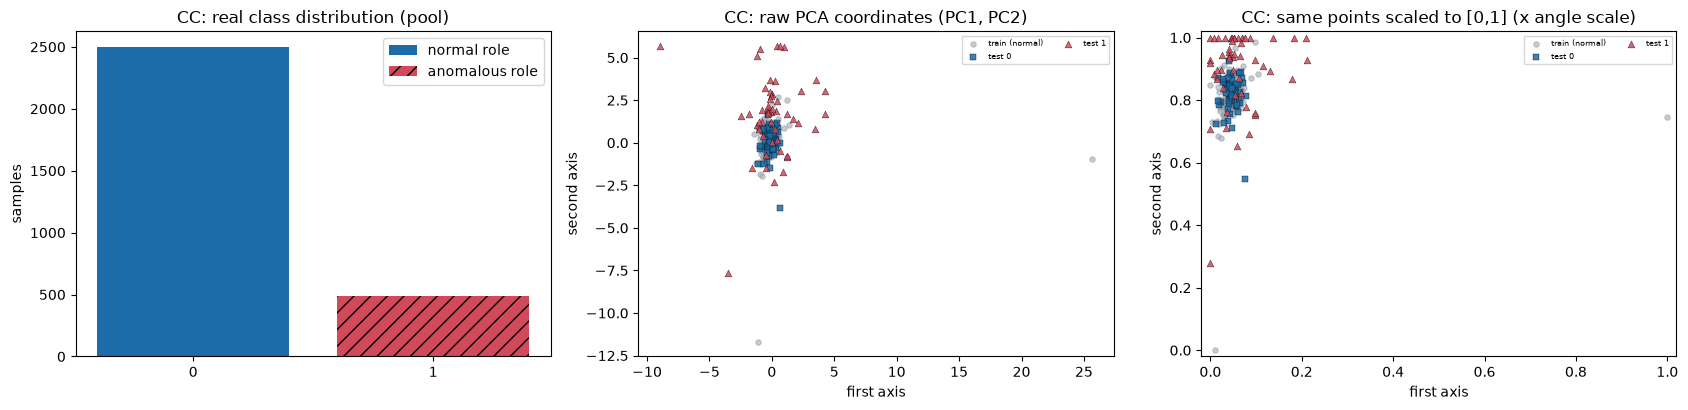

  PCA(5) explained variance ratio (fitted on 100 training normals): [0.239 0.07  0.063 0.061 0.059]


Census: OpenML 1590 adult/census income: <=50K normal, >50K anomalous; categoricals one-hot encoded  (loaded in 1s)
  shape: normal pool (2500, 105), anomalous pool (800, 105) (pools are capped at 2500/800 rows)
  features (105): ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week', 'workclass_Federal-gov', 'workclass_Local-gov', 'workclass_Never-worked', 'workclass_Private', 'workclass_Self-emp-inc', 'workclass_Self-emp-not-inc'] ...
  original labels, normal role   : {'<=50K': np.int64(2500)}
  original labels, anomalous role: {'>50K': np.int64(800)}


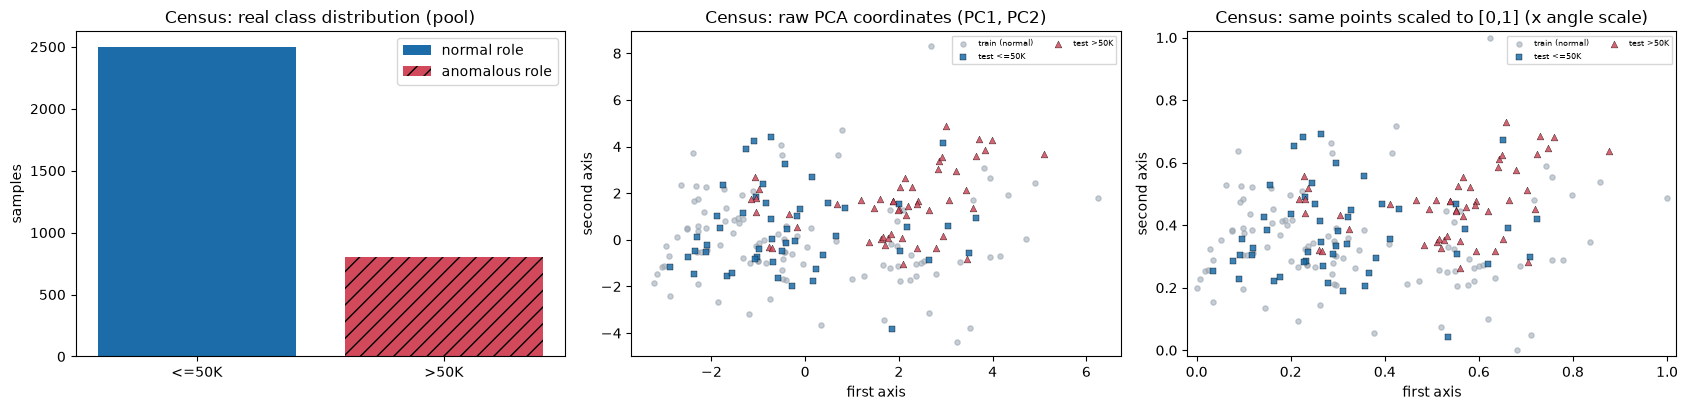

  PCA(5) explained variance ratio (fitted on 100 training normals): [0.076 0.056 0.051 0.047 0.043]


CoverT: Forest cover type: classes 1-4 normal, 5-7 anomalous (as in the paper)  (loaded in 160s)
  shape: normal pool (2500, 54), anomalous pool (800, 54) (pools are capped at 2500/800 rows)
  features (54): ['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area_0', 'Wilderness_Area_1'] ...
  original labels, normal role   : {1: np.int64(975), 2: np.int64(1322), 3: np.int64(189), 4: np.int64(14)}
  original labels, anomalous role: {5: np.int64(164), 6: np.int64(290), 7: np.int64(346)}


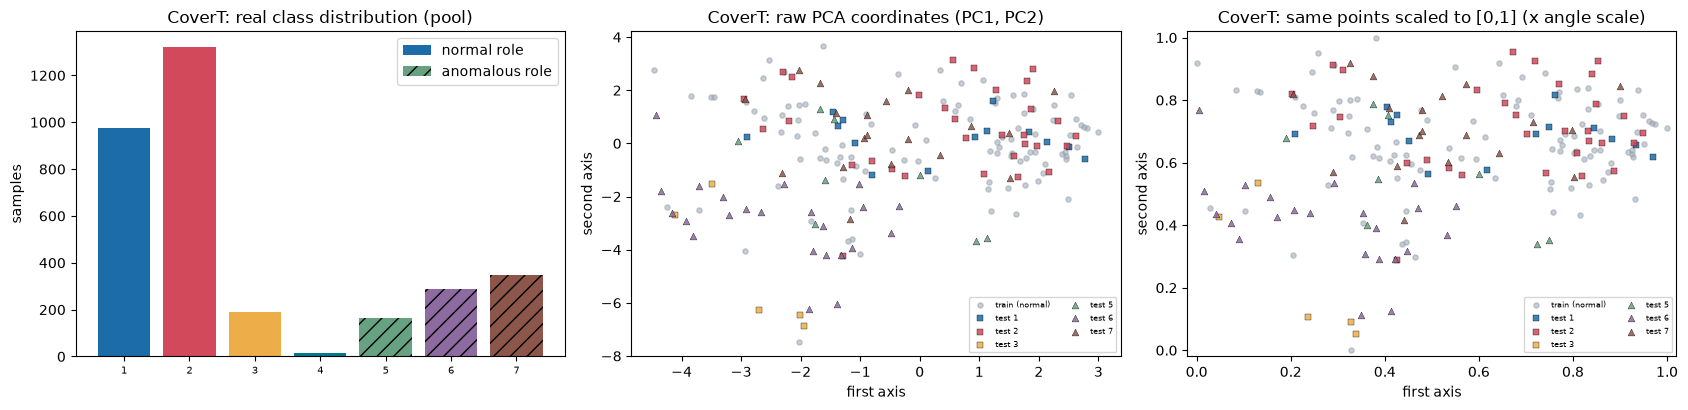

  PCA(5) explained variance ratio (fitted on 100 training normals): [0.105 0.082 0.06  0.053 0.048]


DoH: CIC-DoHBrw-2020 Layer-2 flows (HF mirror c01dsnap/DoHTunnelAnalyzer): Benign vs Malicious  (loaded in 10s)
  shape: normal pool (2500, 29), anomalous pool (800, 29) (pools are capped at 2500/800 rows)
  features (29): ['Duration', 'FlowBytesSent', 'FlowSentRate', 'FlowBytesReceived', 'FlowReceivedRate', 'PacketLengthVariance', 'PacketLengthStandardDeviation', 'PacketLengthMean', 'PacketLengthMedian', 'PacketLengthMode', 'PacketLengthSkewFromMedian', 'PacketLengthSkewFromMode'] ...
  original labels, normal role   : {'Benign': np.int64(2500)}
  original labels, anomalous role: {'Malicious': np.int64(800)}


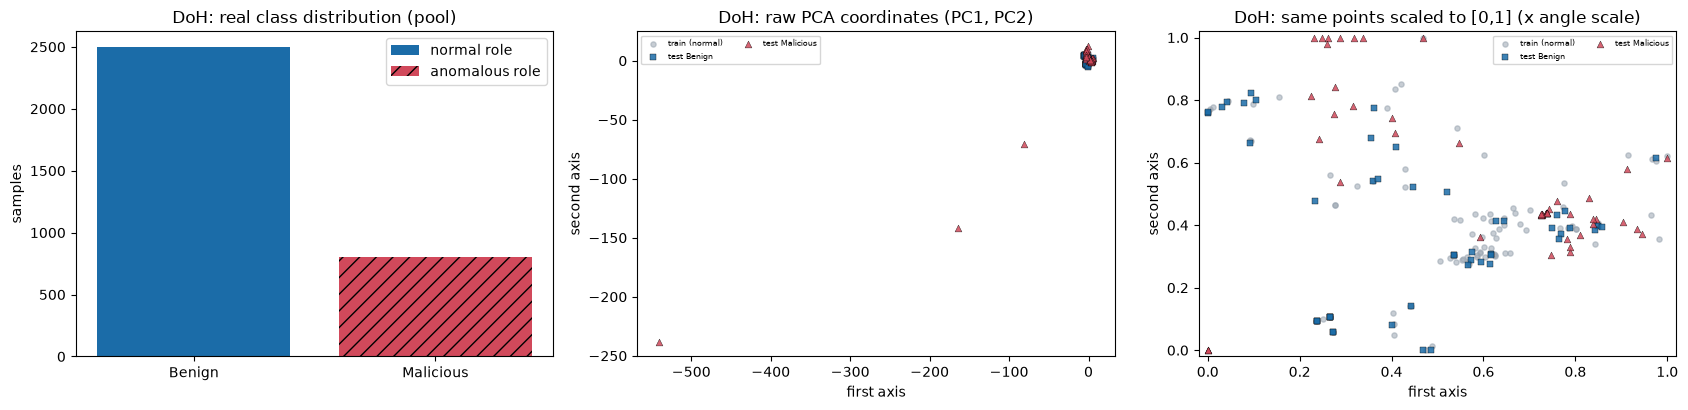

  PCA(5) explained variance ratio (fitted on 100 training normals): [0.244 0.194 0.108 0.089 0.074]


emnist-letters/test-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 8.41MB            

emnist-letters/test-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

emnist-letters/train-00000-of-00001.parq(…): reconstructing file:   0%|          |  0.00B / 50.6MB            

emnist-letters/train-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

EMNIST: EMNIST letters (HF tanganke/emnist_letters): A-M normal, N-Z anomalous  (loaded in 7s)
  shape: normal pool (2500, 784), anomalous pool (800, 784) (pools are capped at 2500/800 rows)
  features (784): ['px0', 'px1', 'px2', 'px3', 'px4', 'px5', 'px6', 'px7', 'px8', 'px9', 'px10', 'px11'] ...
  original labels, normal role   : {0: np.int64(179), 1: np.int64(185), 2: np.int64(221), 3: np.int64(189), 4: np.int64(157), 5: np.int64(200), 6: np.int64(191), 7: np.int64(213), 8: np.int64(186), 9: np.int64(228), 10: np.int64(181), 11: np.int64(184), 12: np.int64(186)}
  original labels, anomalous role: {13: np.int64(73), 14: np.int64(61), 15: np.int64(53), 16: np.int64(49), 17: np.int64(59), 18: np.int64(55), 19: np.int64(73), 20: np.int64(55), 21: np.int64(55), 22: np.int64(65), 23: np.int64(73), 24: np.int64(62), 25: np.int64(67)}


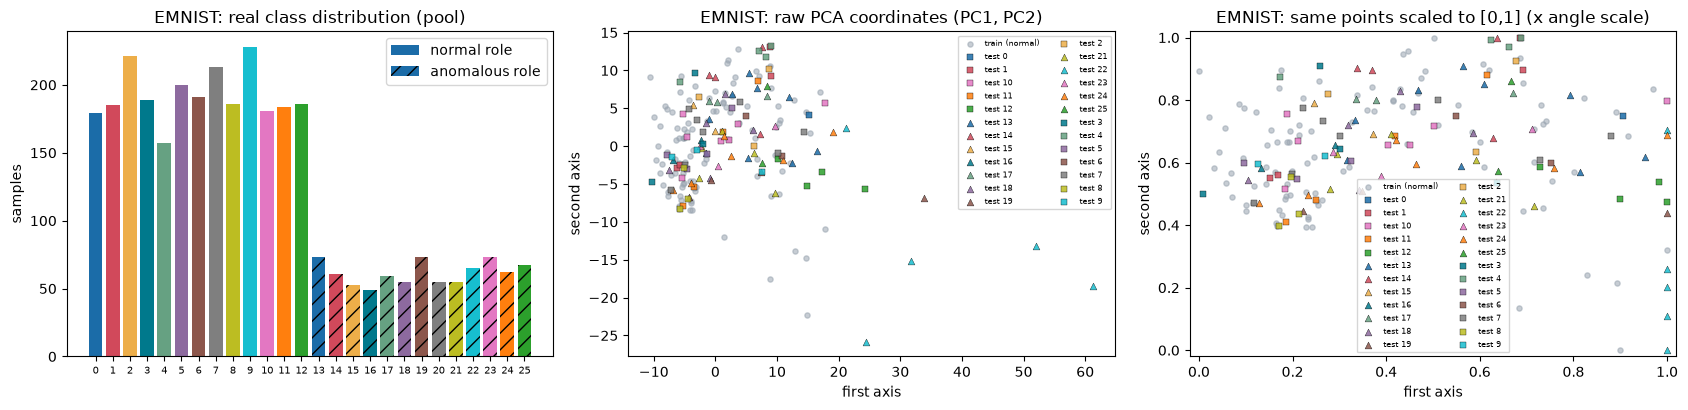

  PCA(5) explained variance ratio (fitted on 100 training normals): [0.083 0.068 0.059 0.045 0.043]


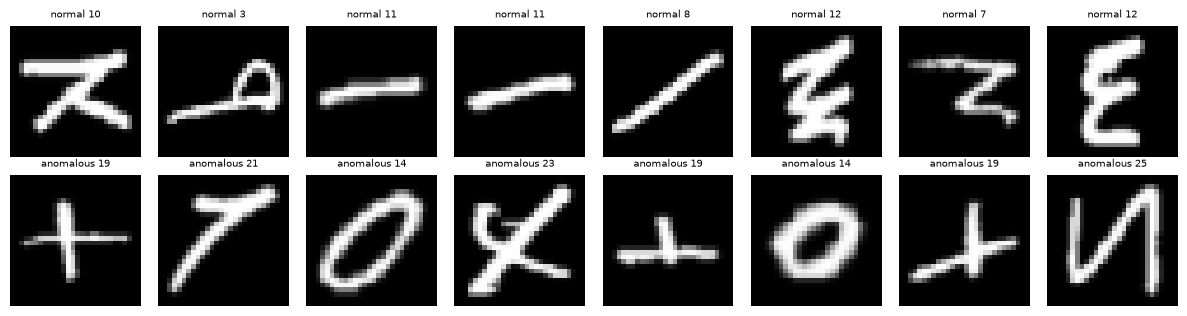

fashion_mnist/train-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 30.9MB            

fashion_mnist/train-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

fashion_mnist/test-00000-of-00001.parque(…): reconstructing file:   0%|          |  0.00B / 5.18MB            

fashion_mnist/test-00000-of-00001.parque(…): downloading bytes:           |  0.00B            

FMNIST: Fashion-MNIST (HF zalando-datasets/fashion_mnist): classes 0-4 normal, 5-9 anomalous  (loaded in 5s)
  shape: normal pool (2500, 784), anomalous pool (800, 784) (pools are capped at 2500/800 rows)
  features (784): ['px0', 'px1', 'px2', 'px3', 'px4', 'px5', 'px6', 'px7', 'px8', 'px9', 'px10', 'px11'] ...
  original labels, normal role   : {0: np.int64(520), 1: np.int64(484), 2: np.int64(520), 3: np.int64(469), 4: np.int64(507)}
  original labels, anomalous role: {5: np.int64(170), 6: np.int64(166), 7: np.int64(135), 8: np.int64(151), 9: np.int64(178)}


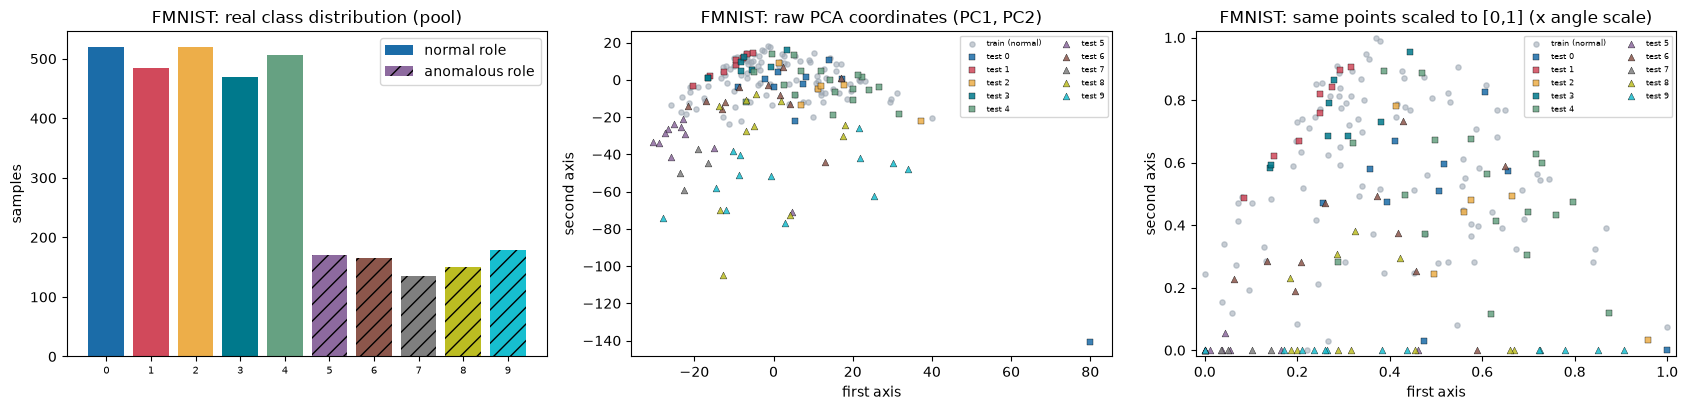

  PCA(5) explained variance ratio (fitted on 100 training normals): [0.259 0.15  0.09  0.056 0.04 ]


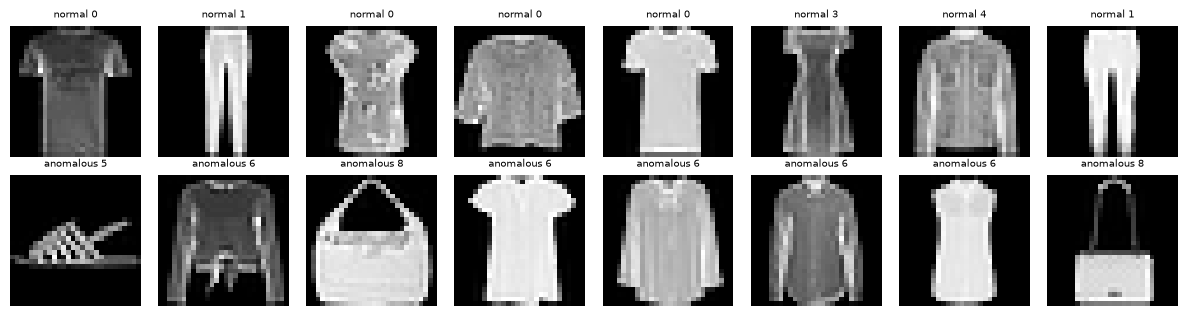

KDD: NSL-KDD (Tavallaee et al. 2009) KDDTrain+: normal vs anomaly; protocol/service/flag one-hot  (loaded in 4s)
  shape: normal pool (2500, 122), anomalous pool (800, 122) (pools are capped at 2500/800 rows)
  features (122): ['duration', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted'] ...
  original labels, normal role   : {'normal': np.int64(2500)}
  original labels, anomalous role: {'anomaly': np.int64(800)}


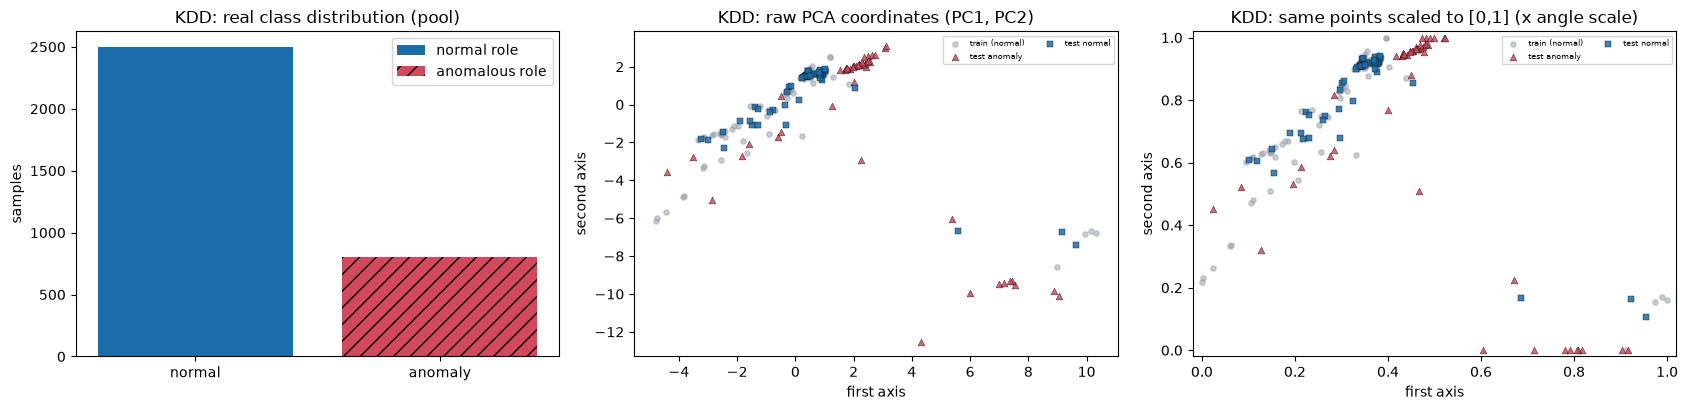

  PCA(5) explained variance ratio (fitted on 100 training normals): [0.16  0.147 0.116 0.07  0.067]


mnist/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.60MB            

mnist/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

MNIST: MNIST digits (HF ylecun/mnist): 0-4 normal, 5-9 anomalous  (loaded in 4s)
  shape: normal pool (2500, 784), anomalous pool (800, 784) (pools are capped at 2500/800 rows)
  features (784): ['px0', 'px1', 'px2', 'px3', 'px4', 'px5', 'px6', 'px7', 'px8', 'px9', 'px10', 'px11'] ...
  original labels, normal role   : {0: np.int64(517), 1: np.int64(542), 2: np.int64(525), 3: np.int64(448), 4: np.int64(468)}
  original labels, anomalous role: {5: np.int64(140), 6: np.int64(165), 7: np.int64(183), 8: np.int64(154), 9: np.int64(158)}


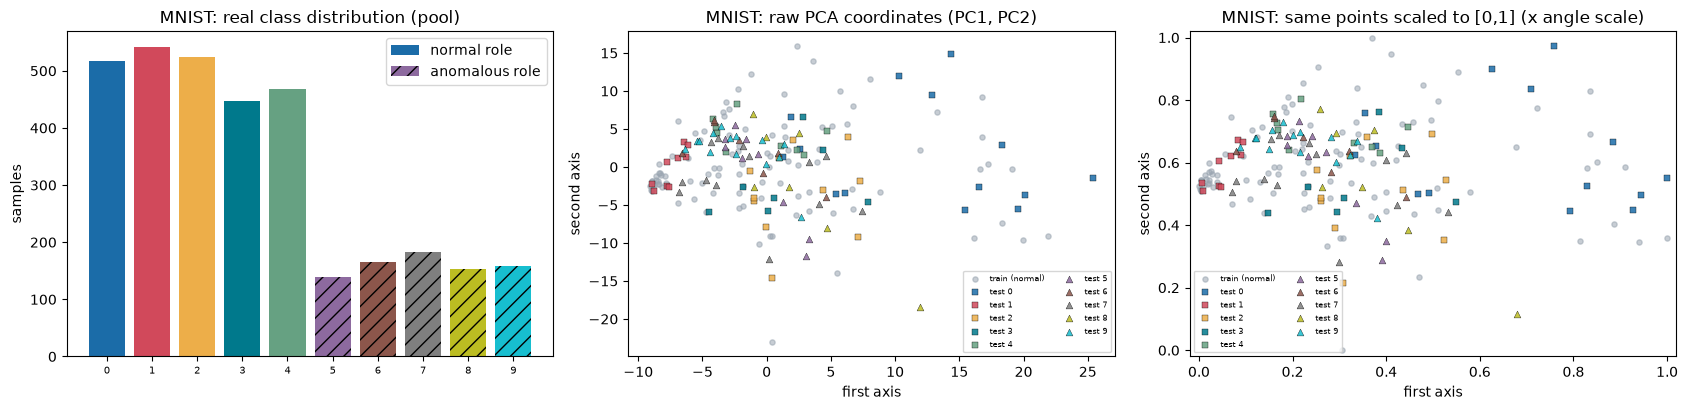

  PCA(5) explained variance ratio (fitted on 100 training normals): [0.122 0.074 0.06  0.052 0.049]


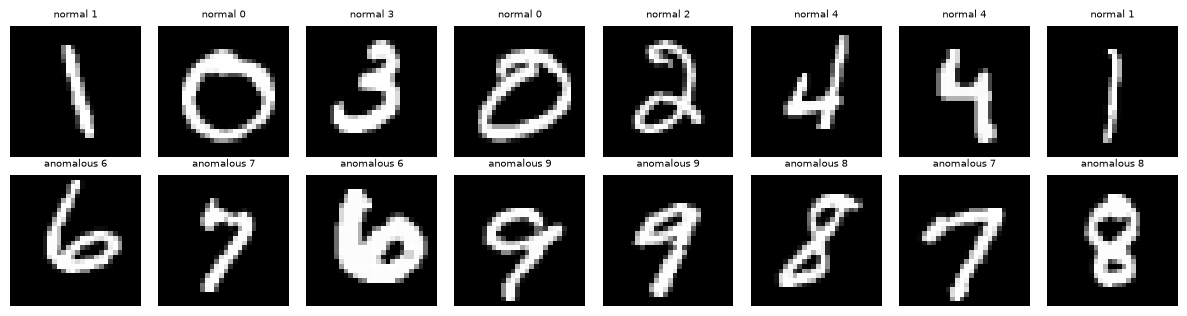

Mammo: OpenML 310 (Woods et al. 1993): '-1' = normal, '1' = malignant calcification  (loaded in 0s)
  shape: normal pool (2500, 6), anomalous pool (260, 6) (pools are capped at 2500/800 rows)
  features (6): ['attr1', 'attr2', 'attr3', 'attr4', 'attr5', 'attr6']
  original labels, normal role   : {'-1': np.int64(2500)}
  original labels, anomalous role: {'1': np.int64(260)}


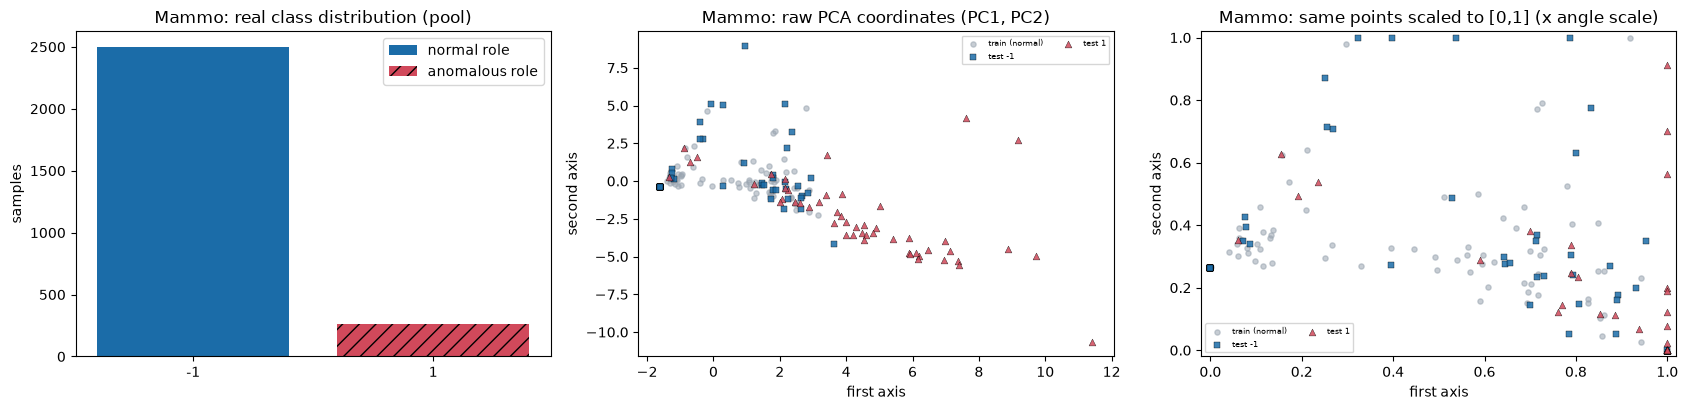

  PCA(5) explained variance ratio (fitted on 100 training normals): [0.428 0.203 0.151 0.127 0.077]
Toy: Synthetic 5-D toy set, linearly separable along f0 with gap 0.4 (reconstruction of the paper's Toy)  (loaded in 0s)
  shape: normal pool (2500, 5), anomalous pool (800, 5) (pools are capped at 2500/800 rows)
  features (5): ['f0', 'f1', 'f2', 'f3', 'f4']
  original labels, normal role   : {'Normal': np.int64(2500)}
  original labels, anomalous role: {'Anomalous': np.int64(800)}


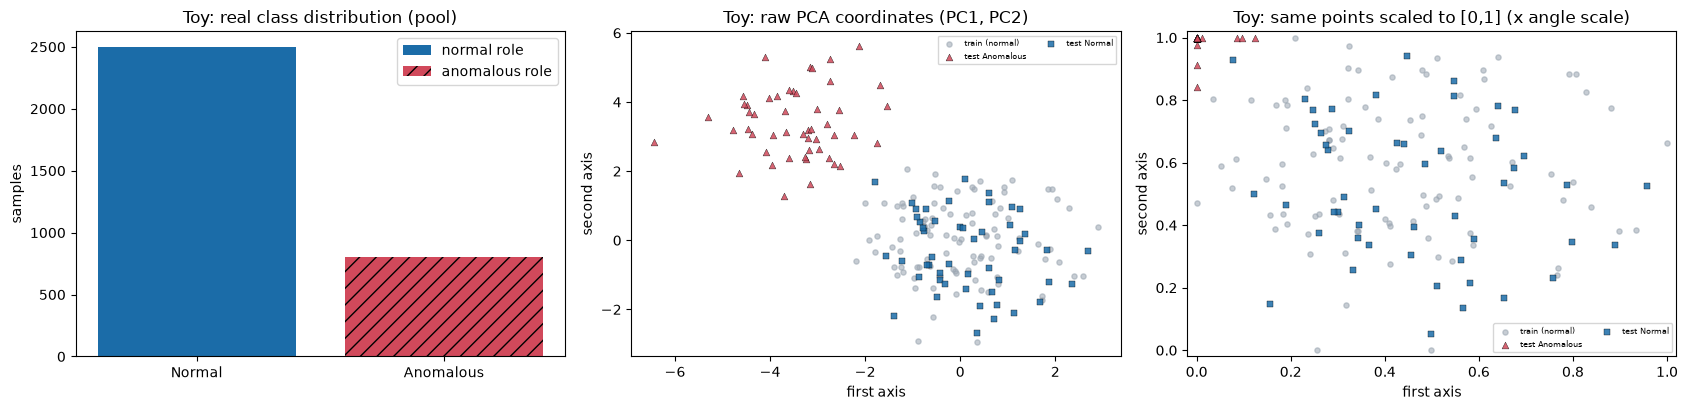

  PCA(5) explained variance ratio (fitted on 100 training normals): [0.251 0.224 0.203 0.169 0.153]


In [8]:
# ---- Dataset Exploration and Visualisation (real observations only) -----------------------------
import gc, matplotlib.pyplot as plt
PALETTE = ["#1b6ca8", "#d1495b", "#edae49", "#00798c", "#66a182", "#8d6a9f", "#8c564b", "#7f7f7f", "#bcbd22", "#17becf",
           "#e377c2", "#ff7f0e", "#2ca02c"]
DATASETS_LOADED = {}
for name in DATASETS:
    t0 = time.time()
    try:
        DATASETS_LOADED[name] = LOADERS[name](np.random.default_rng(SEED))
    except Exception as e:                       # a dataset that cannot be downloaded is reported, never faked
        print(f"[BLOCKED] {name}: {type(e).__name__}: {str(e)[:200]}"); continue
    ds = DATASETS_LOADED[name]
    print("=" * 100); print(f"{name}: {ds['desc']}  (loaded in {time.time() - t0:.0f}s)")
    print(f"  shape: normal pool {ds['Xn'].shape}, anomalous pool {ds['Xa'].shape} (pools are capped at {POOL_NORMAL}/{POOL_ANOM} rows)")
    print(f"  features ({len(ds['features'])}): {ds['features'][:12]}{' ...' if len(ds['features']) > 12 else ''}")
    lab_n, lab_a = pd.Series(ds["yn"]).value_counts().sort_index(), pd.Series(ds["ya"]).value_counts().sort_index()
    print("  original labels, normal role   :", dict(lab_n)); print("  original labels, anomalous role:", dict(lab_a))

    sp = make_split(ds, SEED); fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
    labs = list(lab_n.index) + list(lab_a.index); cols = {l: PALETTE[i % len(PALETTE)] for i, l in enumerate(labs)}
    ax[0].bar([str(l) for l in lab_n.index], lab_n.values, color=[cols[l] for l in lab_n.index], label="normal role")
    ax[0].bar([str(l) for l in lab_a.index], lab_a.values, color=[cols[l] for l in lab_a.index], hatch="//", label="anomalous role")
    ax[0].set_title(f"{name}: real class distribution (pool)"); ax[0].set_ylabel("samples"); ax[0].legend()
    if len(labs) > 6: ax[0].tick_params(axis="x", labelsize=7)
    tr_raw, te_raw = sp["raw_tr"][:, :2], sp["raw_te"][:, :2]
    ang_tr, ang_te = sp["Xtr"][:, :2], sp["Xte"][:, :2]
    for a_, (A, B_, ttl, lim) in zip(ax[1:], [(tr_raw, te_raw, "raw PCA coordinates (PC1, PC2)", None),
                                              (ang_tr, ang_te, "same points scaled to [0,1] (x angle scale)", (-0.02, 1.02))]):
        a_.scatter(A[:, 0], A[:, 1], c="#9aa5b1", s=14, marker="o", alpha=.55, label="train (normal)")
        for l in sorted(set(sp["lab_te"]), key=str):
            m = sp["lab_te"] == l
            a_.scatter(B_[m, 0], B_[m, 1], c=cols.get(l, "k"), s=24, marker="^" if l in lab_a.index else "s", alpha=.85,
                       edgecolor="k", linewidth=.3, label=f"test {l}")
        a_.set_title(f"{name}: {ttl}"); a_.set_xlabel("first axis"); a_.set_ylabel("second axis")
        if lim: a_.set_xlim(lim); a_.set_ylim(lim)
        a_.legend(fontsize=6, ncol=2, loc="best")
    plt.tight_layout(); plt.show()
    print(f"  PCA(5) explained variance ratio (fitted on {N_TRAIN} training normals): {np.round(sp['pca_var'], 3)}")
    if ds.get("img_shape"):                       # images: also show real samples of both roles
        fig, ax = plt.subplots(2, 8, figsize=(12, 3.2)); rg = np.random.default_rng(SEED)
        for r_, (X_, y_, t_) in enumerate([(ds["Xn"], ds["yn"], "normal"), (ds["Xa"], ds["ya"], "anomalous")]):
            for c_, i_ in enumerate(rg.choice(len(X_), 8, replace=False)):
                ax[r_, c_].imshow(X_[i_].reshape(ds["img_shape"]), cmap="gray"); ax[r_, c_].axis("off"); ax[r_, c_].set_title(f"{t_} {y_[i_]}", fontsize=7)
        plt.tight_layout(); plt.show()
    del sp; gc.collect()


## Quantum Circuit Architecture

The kernel circuit has five qubits and no trainable gate: every angle is a (product of) input feature(s). Reading from the left: `RZ(a_i)` and `RX(a_i)` on each qubit encode the five features, a chain of `IsingZZ(a_i a_{i+1})` gates entangles neighbours (the paper's Fig. 1 does not show which pairs are coupled, so a linear chain is assumed, `# CHOICE`), and then the adjoint of the same block with the second sample's features undoes the first. The probability of measuring `00000` is the kernel value. Qiskit's `RZZ(theta)` equals PennyLane's `IsingZZ(theta)` = `exp(-i theta/2 Z(x)Z)`.

The cell draws (1) the Qiskit kernel circuit with symbolic parameters `x` (first sample) and `y` (second sample), (2) the PennyLane QNode that implements the same gates, (3) the PennyLane noisy QNode with a depolarizing channel after every gate (the circuit simulated for the noise study), and asserts that the numpy simulator used in all experiments agrees with Qiskit and with PennyLane `default.mixed` for all six noise channels. There is one architecture only, so one drawing per framework suffices. The circuit that is executed on the noisy fake IBM device (after transpilation) is drawn in section 7.

In [9]:
# ---- Circuits actually executed: Qiskit kernel circuit, PennyLane QNode (noiseless + noisy) -----
import matplotlib
import pennylane as qml
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector

def fm_qiskit(qc, a):
    for i in range(NQ): qc.rz(a[i], i)
    for i in range(NQ): qc.rx(a[i], i)
    for (i, j) in PAIRS: qc.rzz(a[i] * a[j], i, j)          # RZZ(theta) = exp(-i theta/2 Z(x)Z) = PennyLane IsingZZ(theta)

def kernel_circuit_qiskit(measure=True):
    x, y = ParameterVector("x", NQ), ParameterVector("y", NQ)
    qc = QuantumCircuit(NQ, NQ if measure else 0)
    fm_qiskit(qc, x)                                          # U(x_i)
    inv = QuantumCircuit(NQ); fm_qiskit(inv, y); qc.compose(inv.inverse(), inplace=True)   # U(x_j)^dagger
    if measure: qc.measure(range(NQ), range(NQ))
    return qc, x, y

def kernel_qiskit_value(a, b):
    qc, x, y = kernel_circuit_qiskit(measure=False)
    qc = qc.assign_parameters(dict(zip(list(x) + list(y), list(a) + list(b))))
    return float(Statevector(qc).probabilities()[0])

dev_pure = qml.device("default.qubit", wires=NQ)
def fm_pl(a):
    for i in range(NQ): qml.RZ(a[i], wires=i)
    for i in range(NQ): qml.RX(a[i], wires=i)
    for (i, j) in PAIRS: qml.IsingZZ(a[i] * a[j], wires=[i, j])

@qml.qnode(dev_pure)
def kernel_qnode(a, b):
    fm_pl(a); qml.adjoint(fm_pl)(b)
    return qml.probs(wires=range(NQ))

dev_mixed = qml.device("default.mixed", wires=NQ)
def _noise_pl(channel, p, wires):
    for w in wires:
        if channel == "bit_flip": qml.BitFlip(p, wires=w)
        elif channel == "phase_flip": qml.PhaseFlip(p, wires=w)
        elif channel == "depolarizing": qml.DepolarizingChannel(p, wires=w)
        elif channel == "phase_damping": qml.PhaseDamping(p, wires=w)
        elif channel == "amplitude_damping": qml.AmplitudeDamping(p, wires=w)
        elif channel == "miscalibration": qml.RX(p, wires=w)

def _gates_pl(a):
    return [("RZ", (i,), a[i]) for i in range(NQ)] + [("RX", (i,), a[i]) for i in range(NQ)] \
         + [("ZZ", (i, j), a[i] * a[j]) for (i, j) in PAIRS]

def _apply_pl(kind, w, t):
    if kind == "RZ": qml.RZ(t, wires=w[0])
    elif kind == "RX": qml.RX(t, wires=w[0])
    else: qml.IsingZZ(t, wires=list(w))

@qml.qnode(dev_mixed)
def noisy_kernel_qnode(a, b, channel="depolarizing", p=0.05):
    """Same gates as kernel_qnode, followed by a noise channel after every gate on every wire it touches."""
    for (k, w, t) in _gates_pl(a):                         # U(a)
        _apply_pl(k, w, t); _noise_pl(channel, p, w)
    for (k, w, t) in _gates_pl(b)[::-1]:                   # U(b)^dagger = reversed gates with negated angles
        _apply_pl(k, w, -t); _noise_pl(channel, p, w)
    return qml.probs(wires=range(NQ))


QISKIT kernel circuit  U(x_i) then U(x_j)^dagger, measure all qubits
  qubits = 5 | depth = 13 (without measurement: 12) | gates = 28 | data-encoding parameters = 10 (x:5 + y:5)
  trainable quantum parameters = 0  (the feature map is fixed; the only trained objects are the classical SVR dual weights)
  gate counts: {'rz': 10, 'rx': 10, 'rzz': 8}


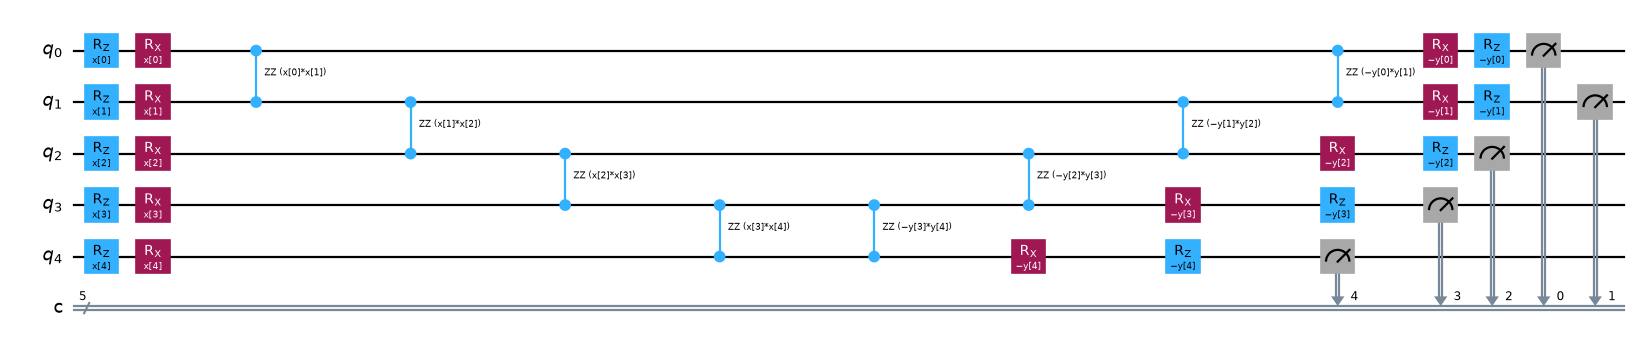


PENNYLANE kernel QNode (default.qubit), identical gate list


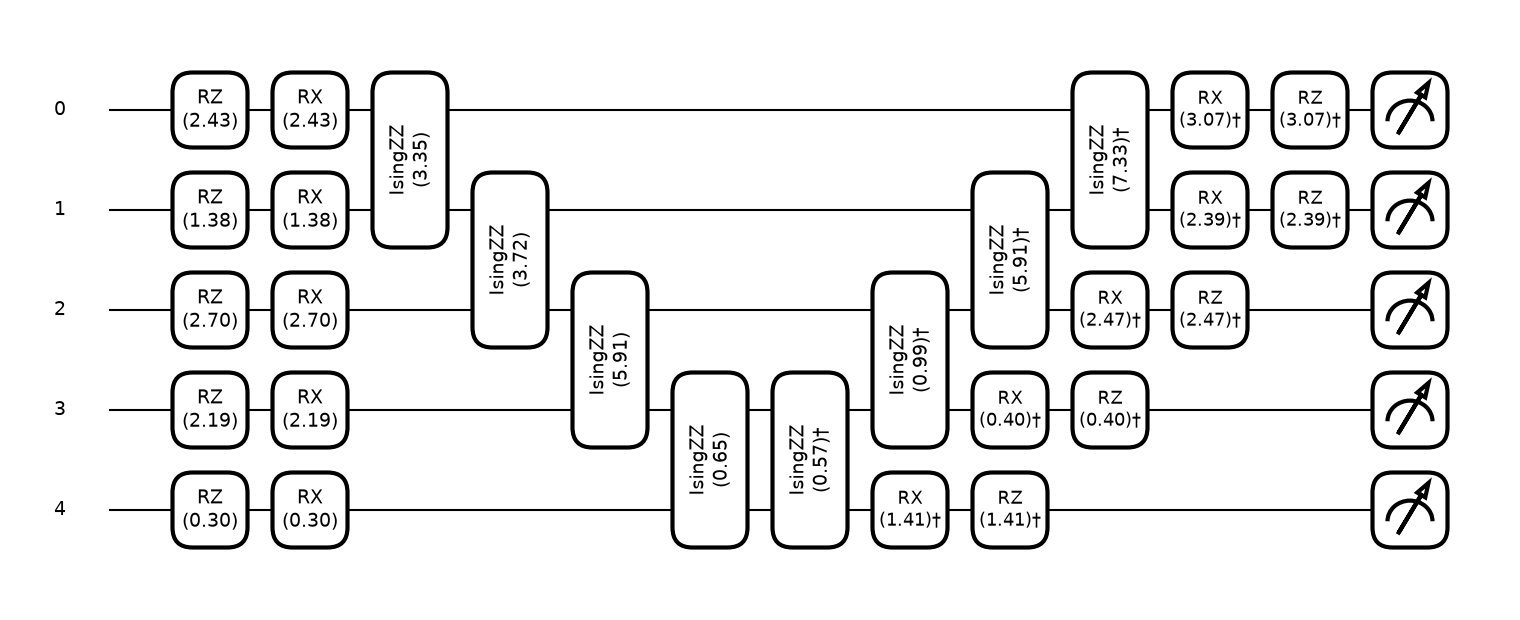

  wires = 5 | depth = 12 | gates = 28

PENNYLANE noisy kernel QNode (default.mixed), depolarizing channel after every gate on every wire it touches


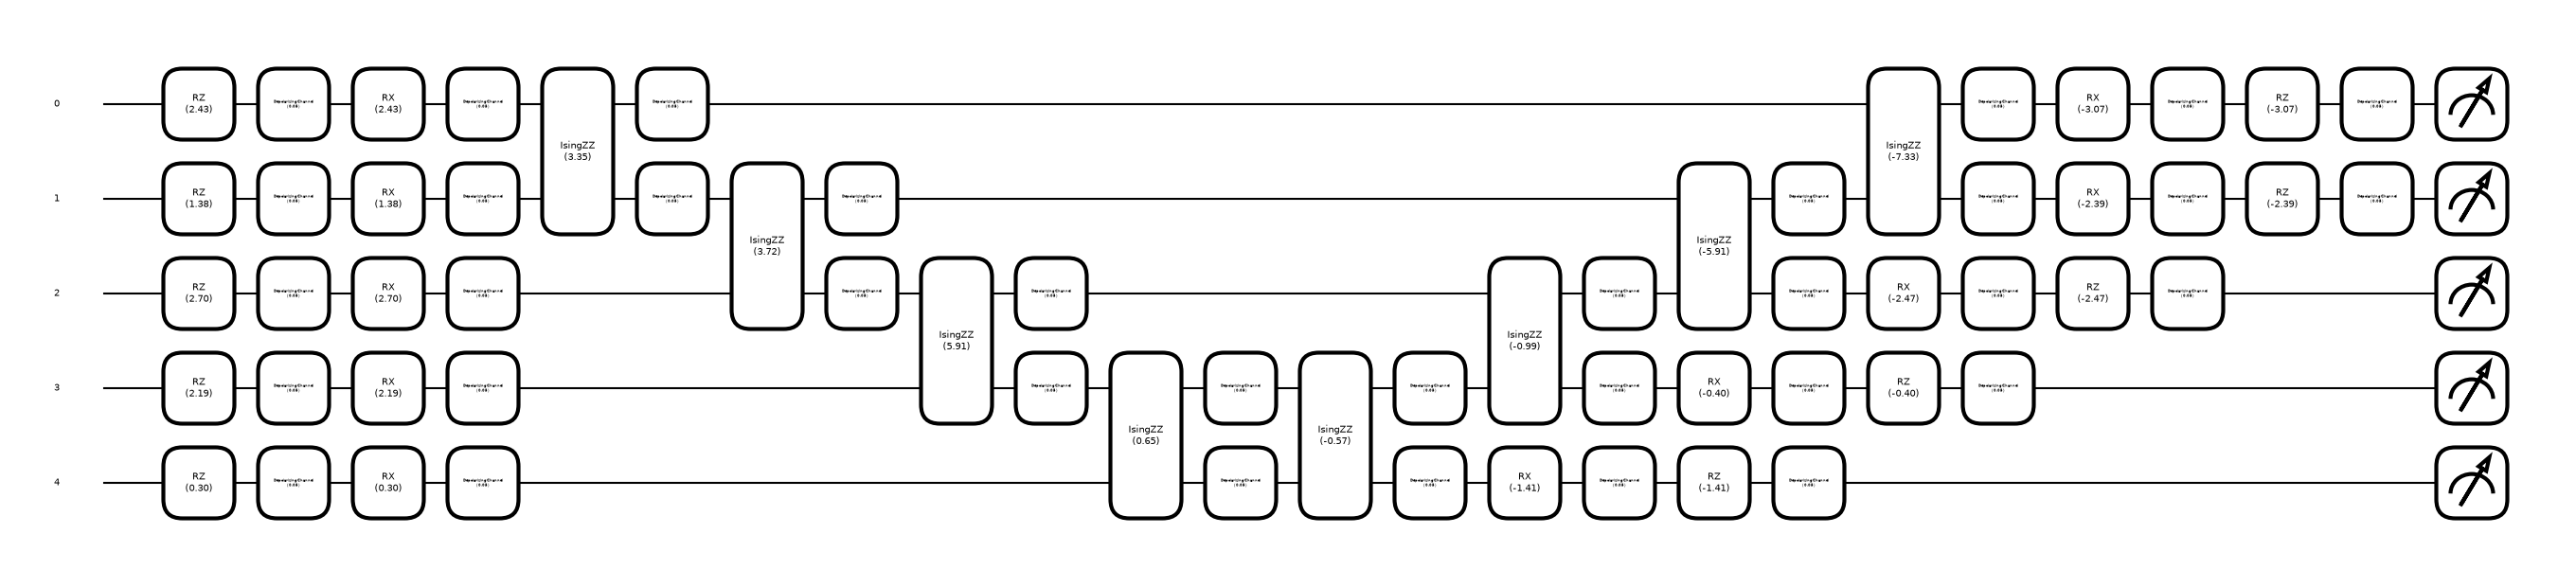

noiseless kernel: numpy == Qiskit == PennyLane (max difference 2.1e-17)
noisy kernel, bit_flip           p=0.1: numpy density-matrix 0.045245 == PennyLane default.mixed 0.045245


noisy kernel, phase_flip         p=0.1: numpy density-matrix 0.062154 == PennyLane default.mixed 0.062154
noisy kernel, depolarizing       p=0.1: numpy density-matrix 0.055394 == PennyLane default.mixed 0.055394


noisy kernel, phase_damping      p=0.2: numpy density-matrix 0.075326 == PennyLane default.mixed 0.075326
noisy kernel, amplitude_damping  p=0.2: numpy density-matrix 0.137958 == PennyLane default.mixed 0.137958
noisy kernel, miscalibration     p=0.8: numpy density-matrix 0.001728 == PennyLane default.mixed 0.001728


In [10]:
# ---- Draw and verify the circuits that are actually executed ----------------------------------
rg = np.random.default_rng(SEED); SC_DEMO = float(np.pi)                      # angle scale used by default (CHOICE)
xa, xb = rg.uniform(0, 1, NQ), rg.uniform(0, 1, NQ)                           # two example (scaled) samples
a_demo, b_demo = SC_DEMO * xa, SC_DEMO * xb

qc_draw, xs_, ys_ = kernel_circuit_qiskit(measure=True)
qc_nomeas, _, _ = kernel_circuit_qiskit(measure=False)
print("QISKIT kernel circuit  U(x_i) then U(x_j)^dagger, measure all qubits")
print(f"  qubits = {qc_draw.num_qubits} | depth = {qc_draw.depth()} (without measurement: {qc_nomeas.depth()}) | gates = {qc_nomeas.size()} | "
      f"data-encoding parameters = {qc_draw.num_parameters} (x:{len(xs_)} + y:{len(ys_)})")
print("  trainable quantum parameters = 0  (the feature map is fixed; the only trained objects are the classical SVR dual weights)")
print("  gate counts:", dict(qc_nomeas.count_ops()))
fig = qc_draw.draw("mpl", fold=45, scale=0.8); display(fig)

print("\nPENNYLANE kernel QNode (default.qubit), identical gate list")
fig, ax = qml.draw_mpl(kernel_qnode, decimals=2)(a_demo, b_demo); plt.show()
specs = qml.specs(kernel_qnode)(a_demo, b_demo)
print("  wires =", len(dev_pure.wires), "| depth =", specs.resources.depth, "| gates =", specs.resources.num_gates)

print("\nPENNYLANE noisy kernel QNode (default.mixed), depolarizing channel after every gate on every wire it touches")
fig, ax = qml.draw_mpl(noisy_kernel_qnode, decimals=2, fontsize=7)(a_demo, b_demo, channel="depolarizing", p=0.05); plt.show()

# Equivalence checks: numpy simulator used in the experiments == Qiskit circuit == PennyLane QNode, for several random pairs
worst = 0.0
for _ in range(5):
    u, v = rg.uniform(0, 1, NQ), rg.uniform(0, 1, NQ)
    k_np = kernel_noiseless(u[None], v[None], SC_DEMO)[0, 0]
    k_qk = kernel_qiskit_value(SC_DEMO * u, SC_DEMO * v); k_pl = float(kernel_qnode(SC_DEMO * u, SC_DEMO * v)[0])
    worst = max(worst, abs(k_np - k_qk), abs(k_np - k_pl))
assert worst < 1e-9, worst
print(f"noiseless kernel: numpy == Qiskit == PennyLane (max difference {worst:.1e})")
for ch, p_ in [("bit_flip", 0.1), ("phase_flip", 0.1), ("depolarizing", 0.1), ("phase_damping", 0.2), ("amplitude_damping", 0.2), ("miscalibration", 0.8)]:
    k_pl = float(noisy_kernel_qnode(a_demo, b_demo, channel=ch, p=p_)[0]); k_np = kernel_noisy(xa[None], xb[None], SC_DEMO, ch, p_)[0, 0]
    assert abs(k_pl - k_np) < 1e-9, (ch, k_pl, k_np)
    print(f"noisy kernel, {ch:18s} p={p_}: numpy density-matrix {k_np:.6f} == PennyLane default.mixed {k_pl:.6f}")


## 3. Noise-free benchmark, PGD attacks, adversarial training and the noise sweep

For every dataset (and seed) the loop below

1. splits the data (100 normal training samples, 50 normal validation samples, 100 balanced test samples), fits PCA/scalers on the training samples only and tunes `C`, epsilon on the validation samples;
2. trains the **noise-free QSVR** and records its test AUC, the AUC of the classical references on the identical 5-D inputs, and the AUC under **PGD** for every attack strength;
3. performs **adversarial training** at eps = 0.01 and eps = 0.1 (PGD copies of the training set replace it; the retrained model is attacked white-box again) and records the Table 5 style ratios `tn/(tn+fp)` and `tp/(tp+fn)`;
4. (first seed only) sweeps the **noise channels**: the model is retrained with the noisy kernel for each channel and probability, and evaluated on the clean test set and on the adversarial test set that was crafted against the *noise-free* model.

Progress is printed per dataset.

In [11]:
# ---- Main experiment loop: benchmark, PGD attacks, adversarial training, noise sweep -------------
R_MAIN, R_NOISE, R_TAB3 = [], [], []
EPS_ALL = sorted(set(EPS_CURVE) | set(AT_EPS) | {0.1})
t_run = time.time()
for name, ds in DATASETS_LOADED.items():
    t_ds = time.time()
    for seed in SEEDS:
        sp = make_split(ds, seed); hp = select_hparams(sp); model = train_qsvr(sp, hp); y = sp["yte"]
        a0 = auc(y, score_with(model, sp["Xte"]))
        adv = {e: pgd(model, sp["Xte"], y, e) for e in EPS_ALL}
        row = dict(dataset=name, seed=seed, scale=hp["scale"], C=hp["C"], eps_svr=hp["eps"], QSVR=a0)
        for e in EPS_ALL: row[f"adv_{e}"] = auc(y, score_with(model, adv[e]))
        row.update(classical_baselines(sp, seed))
        # Table 4/5 analogues: the paper does not say which eps they use, so both eps = 0.01 and eps = 0.1 are evaluated  # CHOICE
        for e in AT_EPS:
            row[f"ratio_norm_{e}"], row[f"ratio_anom_{e}"] = classification_ratios(model, sp, adv[e], y)
            # adversarial training: PGD copies of the normal training set replace the training set; the retrained model is attacked white-box
            Xat = pgd(model, sp["Xtr"], np.zeros(len(sp["Xtr"]), int), e)
            m2 = train_qsvr(sp, hp, X_train=Xat); row[f"QSVR_at_{e}"] = auc(y, score_with(m2, sp["Xte"]))
            adv2 = pgd(m2, sp["Xte"], y, e); row[f"adv_at_{e}"] = auc(y, score_with(m2, adv2))
            row[f"ratio_norm_at_{e}"], row[f"ratio_anom_at_{e}"] = classification_ratios(m2, sp, adv2, y)
        R_MAIN.append(row)
        if seed == SEEDS[0]:                                                 # noise sweep on the first seed only
            sets = dict(clean=sp["Xte"], adv=adv[0.1])
            R_NOISE.append(dict(dataset=name, channel="none", p=0.0, clean=a0, adv=row["adv_0.1"]))
            for ch in CHANNELS:
                for p in NOISE_P: R_NOISE.append(dict(dataset=name, channel=ch, p=p, **noisy_aucs(sp, hp, ch, p, sets, y)))
            for p in MISCAL: R_NOISE.append(dict(dataset=name, channel="miscalibration", p=float(p), **noisy_aucs(sp, hp, "miscalibration", p, sets, y)))
            if name == "DoH":                                                # Table 3: adversarial test kernel under miscalibration
                for p in (2.9, 1.7):
                    Kc = kernel_noisy(sp["Xtr"], adv[0.1], hp["scale"], "miscalibration", p)
                    aucp = noisy_aucs(sp, hp, "miscalibration", p, dict(adv=adv[0.1]), y)["adv"]
                    for c in (0, 1): R_TAB3.append(dict(p=p, AUC=aucp, cls=c, mean_kernel=Kc[:, y == c].mean(), std_kernel=Kc[:, y == c].std()))
        del adv, adv2, model, m2; gc.collect()
    print(f"{name:7s} done in {time.time() - t_ds:5.0f}s | mean noiseless AUC over seeds "
          f"{np.mean([r['QSVR'] for r in R_MAIN if r['dataset'] == name]):.3f}", flush=True)
print(f"total experiment time: {(time.time() - t_run) / 60:.1f} min")
df_main, df_noise = pd.DataFrame(R_MAIN), pd.DataFrame(R_NOISE)


CC      done in    91s | mean noiseless AUC over seeds 0.858


Census  done in    99s | mean noiseless AUC over seeds 0.570


CoverT  done in   105s | mean noiseless AUC over seeds 0.759


DoH     done in    97s | mean noiseless AUC over seeds 0.794


EMNIST  done in    94s | mean noiseless AUC over seeds 0.580


...

KDD     done in    94s | mean noiseless AUC over seeds 0.971


MNIST   done in    92s | mean noiseless AUC over seeds 0.539


Mammo   done in    87s | mean noiseless AUC over seeds 0.837


Toy     done in    97s | mean noiseless AUC over seeds 1.000


total experiment time: 15.8 min


## 4. Re-drawing the paper's figures

* **Fig. 2 analogue.** AUC of the simulated QSVR next to the classical references. The paper's QAE, CAE and the real-hardware bars are not reproduced here. Random Forest and SVC(rbf) are *supervised* references that also see 50 labelled anomalies, so they are upper bounds, not competitors in the semi-supervised setting.
* **Fig. 3 analogue.** AUC against the noise probability for the five incoherent channels (and, separately, over-rotation for miscalibration), clean (solid) and attacked with eps = 0.1 (dashed).
* **Fig. 4 analogue.** AUC of the noise-free model against the attack strength.

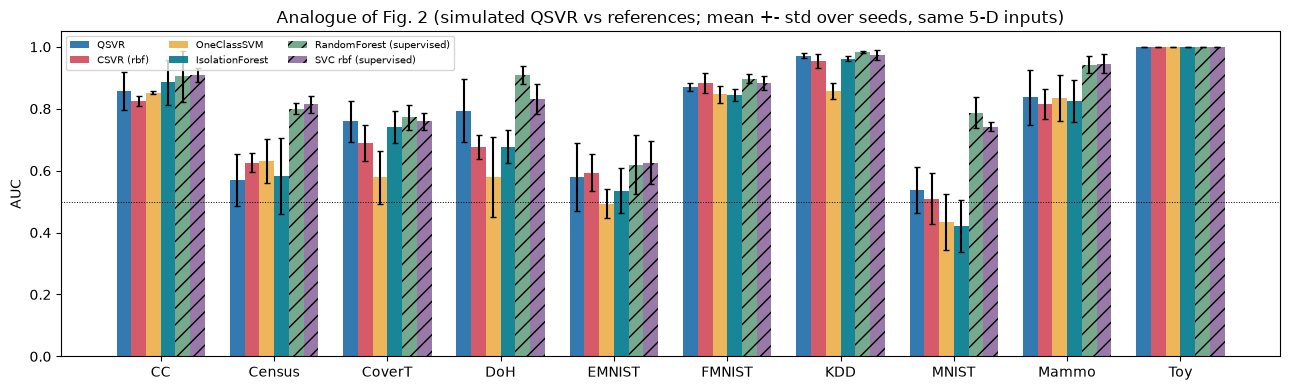

mean AUC over datasets: {'QSVR': 0.778, 'CSVR (rbf)': 0.757, 'OneClassSVM': 0.711, 'IsolationForest': 0.747, 'RandomForest (supervised)': 0.862, 'SVC rbf (supervised)': 0.848}


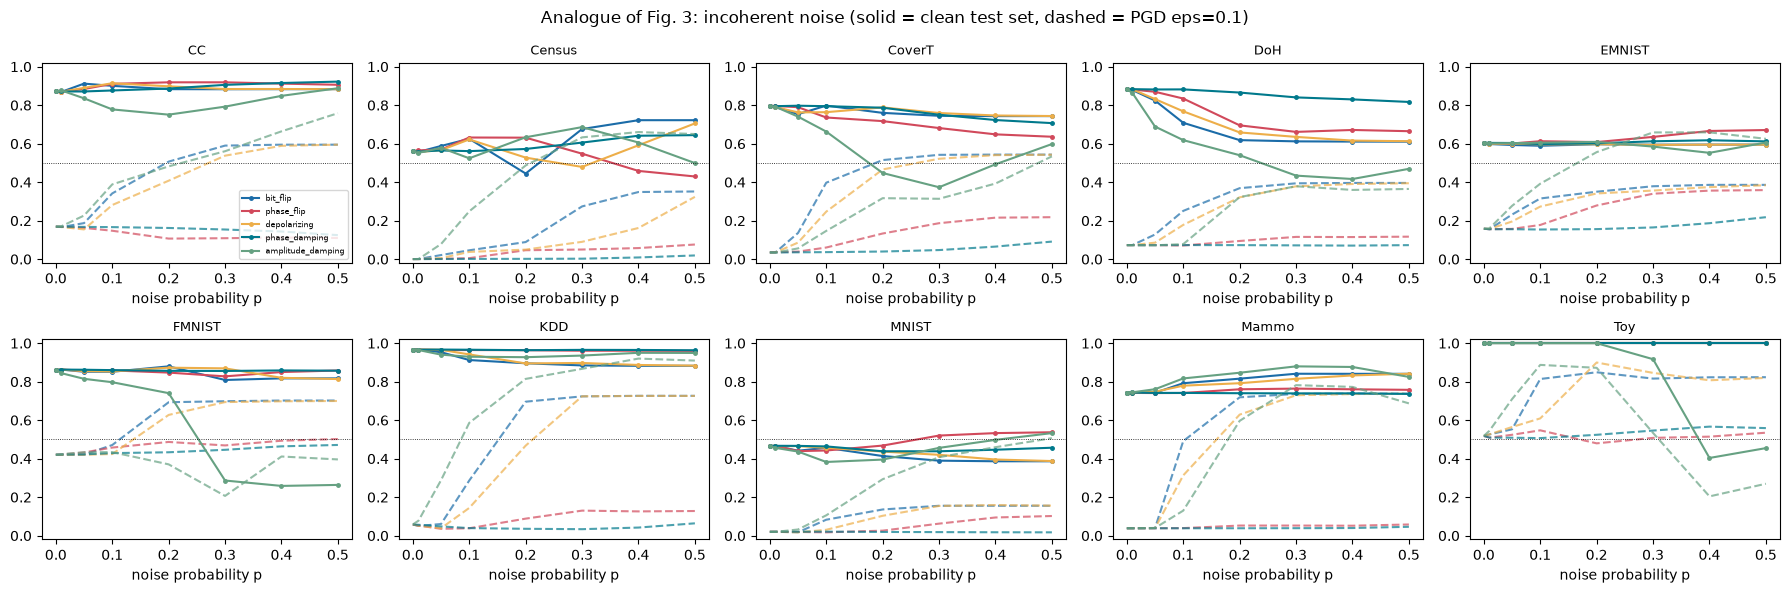

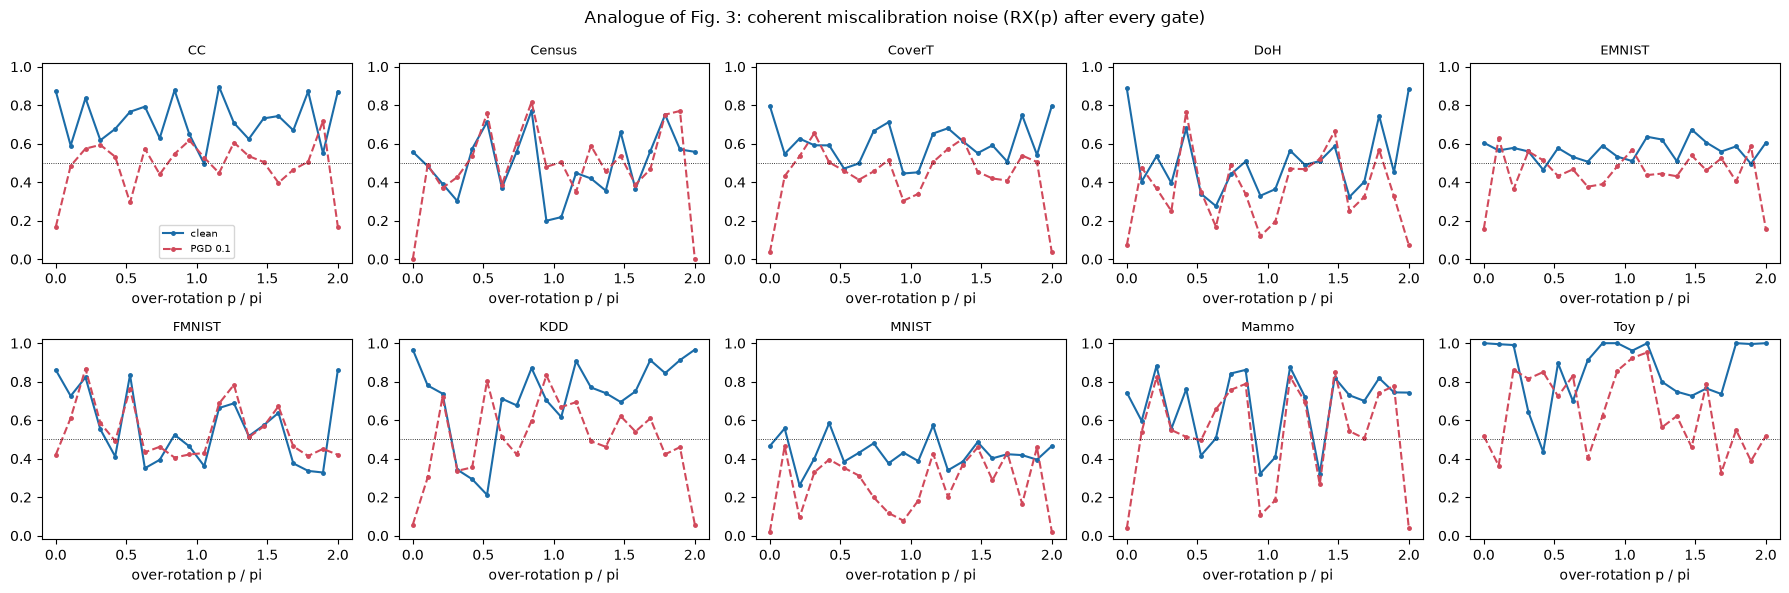

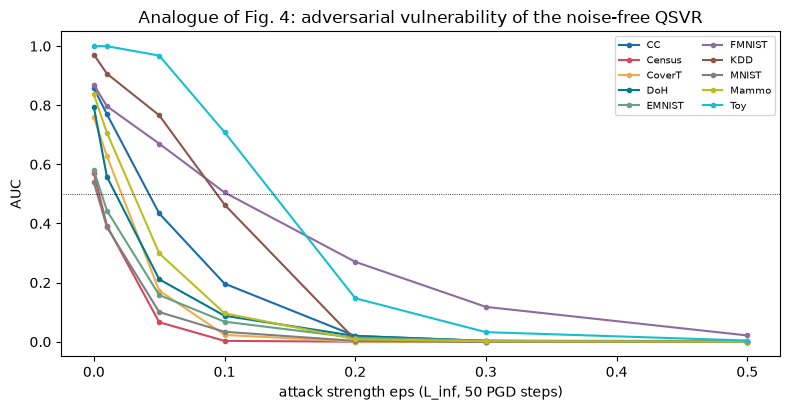

In [12]:
# ---- Re-drawing the paper's figures (Fig. 2, Fig. 3, Fig. 4) from our own numbers ----------------
cols_models = ["QSVR", "CSVR (rbf)", "OneClassSVM", "IsolationForest", "RandomForest (supervised)", "SVC rbf (supervised)"]
agg = df_main.groupby("dataset")[cols_models].agg(["mean", "std"]).fillna(0)
order = [d for d in DATASETS if d in agg.index]
fig, ax = plt.subplots(figsize=(13, 4))
w = 0.13
for k, m in enumerate(cols_models):
    ax.bar(np.arange(len(order)) + (k - 2.5) * w, [agg.loc[d, (m, "mean")] for d in order], w, yerr=[agg.loc[d, (m, "std")] for d in order],
           label=m, hatch="//" if "supervised" in m else None, color=PALETTE[k], capsize=2, alpha=.9)
ax.axhline(0.5, color="k", lw=.7, ls=":"); ax.set_xticks(np.arange(len(order))); ax.set_xticklabels(order); ax.set_ylabel("AUC")
ax.set_title("Analogue of Fig. 2 (simulated QSVR vs references; mean +- std over seeds, same 5-D inputs)"); ax.legend(fontsize=7, ncol=3); plt.tight_layout(); plt.show()
print("mean AUC over datasets:", {m: round(float(np.mean([agg.loc[d, (m, 'mean')] for d in order])), 3) for m in cols_models})

# Fig. 3 analogue: noise channels, clean (solid) and attacked with eps = 0.1 (dashed)
inc = [c for c in CHANNELS]
n_ds = len(order); ncol = min(5, n_ds); nrow = int(np.ceil(n_ds / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 3.0 * nrow), squeeze=False)
for a_, d in zip(axes.ravel(), order):
    z = df_noise[df_noise.dataset == d]; z0 = z[z.channel == "none"].iloc[0]
    for k, ch in enumerate(inc):
        q = z[z.channel == ch].sort_values("p"); xs = np.r_[0, q.p.values]
        a_.plot(xs, np.r_[z0.clean, q.clean.values], "-o", ms=2.5, color=PALETTE[k], label=ch)
        a_.plot(xs, np.r_[z0.adv, q.adv.values], "--", color=PALETTE[k], alpha=.7)
    a_.axhline(0.5, color="k", lw=.6, ls=":"); a_.set_ylim(-0.02, 1.02); a_.set_title(d, fontsize=9); a_.set_xlabel("noise probability p")
axes.ravel()[0].legend(fontsize=6); [a_.axis("off") for a_ in axes.ravel()[n_ds:]]
fig.suptitle("Analogue of Fig. 3: incoherent noise (solid = clean test set, dashed = PGD eps=0.1)"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 3.0 * nrow), squeeze=False)
for a_, d in zip(axes.ravel(), order):
    q = df_noise[(df_noise.dataset == d) & (df_noise.channel == "miscalibration")].sort_values("p")
    a_.plot(q.p / np.pi, q.clean, "-o", ms=2.5, color=PALETTE[0], label="clean"); a_.plot(q.p / np.pi, q.adv, "--o", ms=2.5, color=PALETTE[1], label="PGD 0.1")
    a_.axhline(0.5, color="k", lw=.6, ls=":"); a_.set_ylim(-0.02, 1.02); a_.set_title(d, fontsize=9); a_.set_xlabel("over-rotation p / pi")
axes.ravel()[0].legend(fontsize=7); [a_.axis("off") for a_ in axes.ravel()[n_ds:]]
fig.suptitle("Analogue of Fig. 3: coherent miscalibration noise (RX(p) after every gate)"); plt.tight_layout(); plt.show()

# Fig. 4 analogue: noise-free QSVR under PGD of growing strength
fig, ax = plt.subplots(figsize=(8, 4.2))
for k, d in enumerate(order):
    z = df_main[df_main.dataset == d]; ys = [z.QSVR.mean()] + [z[f"adv_{e}"].mean() for e in EPS_ALL]
    ax.plot([0] + EPS_ALL, ys, "-o", ms=3, color=PALETTE[k % len(PALETTE)], label=d)
ax.set_xlabel("attack strength eps (L_inf, 50 PGD steps)"); ax.set_ylabel("AUC"); ax.axhline(0.5, color="k", lw=.6, ls=":")
ax.set_title("Analogue of Fig. 4: adversarial vulnerability of the noise-free QSVR"); ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()


## 5. Classical baseline on identical inputs

The table below lists, per dataset, the mean (over seeds) test AUC of the quantum model and of the classical references that see exactly the same 5-D inputs: an RBF-kernel SVR doing the same reconstruction task (the paper's CSVR), a One-Class SVM, an Isolation Forest, and the two supervised classifiers.

In [13]:
tab = df_main.groupby("dataset")[cols_models].mean().loc[[d for d in DATASETS if d in set(df_main.dataset)]]
tab.loc["mean"] = tab.mean(); display(tab.round(3))


,QSVR,CSVR (rbf),OneClassSVM,IsolationForest,RandomForest (supervised),SVC rbf (supervised)
dataset,,,,,,
CC,0.858,0.824,0.851,0.885,0.905,0.909
Census,0.570,0.626,0.630,0.582,0.801,0.814
CoverT,0.759,0.689,0.578,0.741,0.772,0.759
DoH,0.794,0.677,0.580,0.677,0.909,0.831
EMNIST,0.580,0.594,0.493,0.535,0.619,0.625
FMNIST,0.869,0.884,0.847,0.844,0.897,0.882
KDD,0.971,0.955,0.857,0.962,0.983,0.974
MNIST,0.539,0.510,0.434,0.421,0.787,0.742
Mammo,0.837,0.816,0.835,0.825,0.942,0.946


## 6. Does the classical model suffer the same way? (extra, cheap check)

The paper attacks only the QSVR. Using the same PGD budget on a classical RBF-SVR (finite-difference-free analytic gradient through the RBF kernel) shows whether the fragility is specific to the quantum kernel. This is an addition of the notebook, not a claim of the paper.

In [14]:
# Same PGD on the classical RBF-SVR reconstruction model (analytic RBF gradients; attacks the same test samples)
def classical_pgd_auc(ds, seed, eps, gamma=2.0, C=10.0):
    sp = make_split(ds, seed); y = sp["yte"]; Xtr = sp["Xtr"]
    ms = [SVR(kernel="rbf", gamma=gamma, C=C, epsilon=0.01).fit(Xtr, Xtr[:, k]) for k in range(N_QUBITS)]
    A = np.zeros((len(Xtr), N_QUBITS)); b = np.zeros(N_QUBITS)
    for k, m in enumerate(ms): A[m.support_, k] = m.dual_coef_[0]; b[k] = m.intercept_[0]
    def pred(X): return np.exp(-gamma * ((X[:, None, :] - Xtr[None]) ** 2).sum(-1)) @ A + b
    def grad(X):
        Kx = np.exp(-gamma * ((X[:, None, :] - Xtr[None]) ** 2).sum(-1)); r = X - (Kx @ A + b)       # (n,5)
        dK = -2 * gamma * (X[:, None, :] - Xtr[None]) * Kx[:, :, None]                                 # (n,m,5)
        return 2 * r - 2 * np.einsum("nk,mk,nmd->nd", r, A, dK)
    sgn = np.where(y == 0, 1.0, -1.0)[:, None]; x = sp["Xte"].copy(); X0 = x.copy()
    for _ in range(PGD_STEPS):
        x = np.clip(np.clip(x + sgn * eps / PGD_STEPS * np.sign(grad(x)), X0 - eps, X0 + eps), 0, 1)
    sc = lambda X: ((X - pred(X)) ** 2).sum(1)
    return auc(y, sc(X0)), auc(y, sc(x))
rows = []
for d in [d for d in DATASETS if d in DATASETS_LOADED]:
    for e in (0.01, 0.1):
        c0, ca = classical_pgd_auc(DATASETS_LOADED[d], SEEDS[0], e)
        rows.append(dict(dataset=d, eps=e, CSVR_clean=c0, CSVR_attacked=ca, QSVR_clean=df_main[(df_main.dataset == d) & (df_main.seed == SEEDS[0])].QSVR.iloc[0],
                         QSVR_attacked=df_main[(df_main.dataset == d) & (df_main.seed == SEEDS[0])][f"adv_{e}"].iloc[0]))
display(pd.DataFrame(rows).round(3))


,dataset,eps,CSVR_clean,CSVR_attacked,QSVR_clean,QSVR_attacked
0,CC,0.01,0.856,0.712,0.872,0.739
1,CC,0.10,0.856,0.140,0.872,0.169
2,Census,0.01,0.585,0.436,0.560,0.418
3,Census,0.10,0.585,0.004,0.560,0.000
4,CoverT,0.01,0.766,0.658,0.796,0.664
5,CoverT,0.10,0.766,0.055,0.796,0.035
6,DoH,0.01,0.639,0.415,0.884,0.550
7,DoH,0.10,0.639,0.064,0.884,0.073
8,EMNIST,0.01,0.684,0.567,0.605,0.514
9,EMNIST,0.10,0.684,0.169,0.605,0.158


## 7. Hardware-style run on a noisy fake IBM Falcon (stand-in for the Ehningen experiment)

The real device is not available, so the *same* kernel circuit is transpiled to the 27-qubit `FakeKolkataV2` (a Falcon processor of the same family as the Ehningen machine; its calibration-based noise model is used by `AerSimulator.from_backend`) and every kernel entry is estimated from shot counts of the all-zero outcome. We use the paper's hardware protocol (30 normal training samples, 50 test samples with equal class ratio; smaller in `FAST_MODE`), the same hyper-parameters as the ideal simulation of that split, and no error mitigation. Diagonal entries (`x_i = x_j`) are optimised away by the transpiler (`U U^dagger = identity`), so they only carry read-out error (about 0.95); this is also what happens on a real device unless the optimisation is switched off. This does **not** verify the paper's hardware numbers (different device, calibration and mitigation); it only shows the direction and size of the gap between an ideal and a noisy execution.

In [15]:
# ---- "Hardware-like" run on a noisy fake IBM Falcon (no real hardware) ---------------------------
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeKolkataV2

fake_be = FakeKolkataV2()                                # 27-qubit Falcon, same family as IBM Ehningen   # CHOICE
aer_noisy = AerSimulator.from_backend(fake_be)           # calibration-based noise model of that device
HW_LAYOUT = [0, 1, 2, 3, 5]                              # a connected chain on the heavy-hex map (0-1-2-3-5), matches the linear ZZ chain
qc_exec, xp, yp = kernel_circuit_qiskit(measure=True)

def kernel_matrix_aer(A, Bm, scale, symmetric):
    """Kernel entries from shot counts of the TRANSPILED kernel circuit on the noisy fake device."""
    jobs = [(i, j) for i in range(len(A)) for j in range(len(Bm)) if not (symmetric and j < i)]
    K = np.zeros((len(A), len(Bm)))
    for s in range(0, len(jobs), 400):
        part = jobs[s:s + 400]
        cs = [qc_exec.assign_parameters(dict(zip(list(xp) + list(yp), list(scale * A[i]) + list(scale * Bm[j])))) for i, j in part]
        tcs = transpile(cs, fake_be, initial_layout=HW_LAYOUT, optimization_level=1, seed_transpiler=SEED)
        res = aer_noisy.run(tcs, shots=HW_SHOTS, seed_simulator=SEED).result()
        for n, (i, j) in enumerate(part): K[i, j] = res.get_counts(n).get("0" * NQ, 0) / HW_SHOTS
    if symmetric: K = K + K.T - np.diag(np.diag(K))
    return K

R_HW = []
for name in HW_DATASETS:
    if name not in DATASETS_LOADED: continue
    t0 = time.time(); ds = DATASETS_LOADED[name]
    sp = make_split(ds, SEED, n_train=HW_TRAIN, n_val=20, n_test=HW_TEST); hp = select_hparams(sp); y = sp["yte"]
    ideal = auc(y, score_with(train_qsvr(sp, hp), sp["Xte"]))
    Ktr = kernel_matrix_aer(sp["Xtr"], sp["Xtr"], hp["scale"], True); Kte = kernel_matrix_aer(sp["Xtr"], sp["Xte"], hp["scale"], False)
    Alpha, b = fit_qsvr(Ktr, sp["Xtr"], hp["C"], hp["eps"])
    noisy = auc(y, anomaly_score(Kte, sp["Xte"], Alpha, b))
    R_HW.append(dict(dataset=name, n_train=HW_TRAIN, n_test=HW_TEST, shots=HW_SHOTS, AUC_ideal_sim=ideal, AUC_fake_device=noisy,
                     mean_kernel_diag=float(np.mean(np.diag(Ktr)))))
    print(f"{name}: ideal {ideal:.3f} | fake Kolkata {noisy:.3f} | mean K_ii on device {np.mean(np.diag(Ktr)):.3f} | {time.time() - t0:.0f}s", flush=True)
df_hw = pd.DataFrame(R_HW)


CC: ideal 0.814 | fake Kolkata 0.819 | mean K_ii on device 0.948 | 116s


KDD: ideal 0.912 | fake Kolkata 0.909 | mean K_ii on device 0.948 | 114s


DoH: ideal 0.637 | fake Kolkata 0.573 | mean K_ii on device 0.948 | 120s


transpiled circuit: device qubits used = [0, 1, 2, 3, 5] of 27 | depth = 32 | size = 76 | ops = {'rz': 37, 'sx': 20, 'cx': 14, 'measure': 5} | trainable parameters = 0


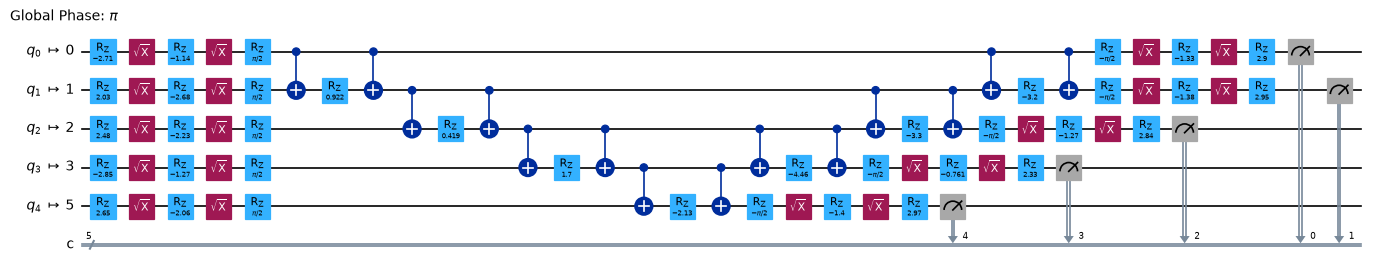

,dataset,n_train,n_test,shots,AUC_ideal_sim,AUC_fake_device,mean_kernel_diag
0,CC,30,50,4096,0.814,0.819,0.948
1,KDD,30,50,4096,0.912,0.909,0.948
2,DoH,30,50,4096,0.637,0.573,0.948


In [16]:
# Draw the circuit that is really executed on the fake device (transpiled kernel circuit for the first two training samples)
if len(df_hw):
    bound = qc_exec.assign_parameters(dict(zip(list(xp) + list(yp), list(hp["scale"] * sp["Xtr"][0]) + list(hp["scale"] * sp["Xtr"][1]))))
    tc = transpile(bound, fake_be, initial_layout=HW_LAYOUT, optimization_level=1, seed_transpiler=SEED)
    active = sorted({tc.find_bit(q).index for inst in tc.data for q in inst.qubits})
    print("transpiled circuit: device qubits used =", active, "of", tc.num_qubits, "| depth =", tc.depth(), "| size =", tc.size(),
          "| ops =", dict(tc.count_ops()), "| trainable parameters = 0")
    display(tc.draw("mpl", idle_wires=False, fold=60, scale=0.6))
    display(df_hw.round(3))


## 8. Side-by-side comparison with the paper

Per-dataset numbers first (Table 4 analogue, Table 5 analogue, Table 3 analogue for DoH), then every checkable claim of the paper with a verdict:
* **reproduced**: our value is within +-0.05 AUC of the paper's (or the qualitative statement holds under the stated numerical test);
* **not reached** / **exceeded**: outside the tolerance, below / above the paper;
* **cannot be checked**: needs the real IBM device or a dataset we did not run.

The verdict text always shows our number next to the paper's, so the size of any gap is visible.

In [17]:
# ---- Side-by-side comparison with the paper (Tables 3, 4, 5 and the text claims) -----------------
# Paper Table 4: (test AUC w/ retraining, test AUC w/o, adversarial AUC w/ retraining, adversarial AUC w/o)
P4 = {"CC": (.85, .90, .37, .31), "Census": (.62, .53, .05, .12), "DoH": (.68, .68, .00, .00), "EMNIST": (.63, .62, .17, .14),
      "FMNIST": (.91, .88, .73, .74), "CoverT": (.44, .56, .18, .08), "KDD": (.71, .90, .46, .43), "Mammo": (.74, .95, .22, .19),
      "MNIST": (.62, .67, .11, .07), "URL": (.59, .60, .08, .08), "Toy": (1.0, 1.0, 1.0, .95)}
# Paper Table 5: (normal ratio w/ retraining, anomaly ratio w/, normal ratio w/o, anomaly ratio w/o)
P5 = {"CC": (.96, .28, .98, .24), "Census": (1, 0, 1, 0), "DoH": (1, 0, 1, 0), "EMNIST": (1, .02, .98, .02), "FMNIST": (.86, .66, .86, .68),
      "CoverT": (1, 0, 1, 0), "KDD": (1, .34, .96, .34), "Mammo": (.96, .18, 1, .14), "MNIST": (1, 0, 1, 0), "URL": (.96, .08, .98, .04),
      "Toy": (.94, 1, .78, 1)}
TOL = 0.05                                                 # CHOICE: AUC on 100 test samples has a standard error of about 0.05
def verdict(ours, paper, tol=TOL):
    if np.isnan(ours): return "cannot be checked"
    d = ours - paper
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")
M = df_main.groupby("dataset").mean(numeric_only=True)
S = df_main.groupby("dataset").std(numeric_only=True).fillna(0)
rows = []
for d in P4:
    if d in M.index:
        r = dict(dataset=d, paper_test=P4[d][1], ours_test=M.loc[d, "QSVR"], std=S.loc[d, "QSVR"], verdict_test=verdict(M.loc[d, "QSVR"], P4[d][1]),
                 paper_adv=P4[d][3], paper_adv_retrain=P4[d][2], paper_test_retrain=P4[d][0])
        for e in AT_EPS:
            r.update({f"ours_adv_{e}": M.loc[d, f"adv_{e}"], f"verdict_adv_{e}": verdict(M.loc[d, f"adv_{e}"], P4[d][3]),
                      f"ours_adv_retrain_{e}": M.loc[d, f"adv_at_{e}"], f"ours_test_retrain_{e}": M.loc[d, f"QSVR_at_{e}"]})
        rows.append(r)
    else:
        rows.append(dict(dataset=d, paper_test=P4[d][1], verdict_test="cannot be checked (dataset not run here)", paper_adv=P4[d][3], paper_adv_retrain=P4[d][2], paper_test_retrain=P4[d][0]))
T4 = pd.DataFrame(rows).set_index("dataset")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
print("Table 4 analogue; tolerance +-%.2f AUC; the attack strength of the paper's Table 4 is not stated, so eps = %s are both shown" % (TOL, AT_EPS)); display(T4.round(3))

have = [d for d in P4 if d in M.index]
claims = []
def add(claim, paper, ours, v): claims.append(dict(claim=claim, paper=paper, notebook=ours, verdict=v))

pm = np.mean([P4[d][1] for d in have]); om = np.mean([M.loc[d, "QSVR"] for d in have])
add(f"Mean noise-free test AUC over the {len(have)} datasets run here", f"{pm:.2f} (Table 4; 0.76 in Sect. 5 over all 11)", f"{om:.2f}", verdict(om, pm))
n_ok = sum(abs(M.loc[d, 'QSVR'] - P4[d][1]) <= TOL for d in have)
add("Per-dataset test AUC within +-0.05 of Table 4", f"{len(have)} datasets", f"{n_ok} of {len(have)}", "reproduced" if n_ok == len(have) else ("partially reproduced" if n_ok else "not reached"))
# --- noise claims
base0 = df_noise[df_noise.channel == "none"].set_index("dataset")
def drift(ch, col="clean"):
    z = df_noise[df_noise.channel == ch]; return float((z[col].values - z.dataset.map(base0[col]).values).mean()), float(np.abs(z[col].values - z.dataset.map(base0[col]).values).mean())
rob = {ch: drift(ch)[1] for ch in ["depolarizing", "phase_damping", "phase_flip", "bit_flip"]}
add("Robust to depolarizing, phase damping, phase flip, bit flip (mean |dAUC| over p and datasets <= 0.10)", "AUC 'rather stable'",
    ", ".join(f"{k} {v:.2f}" for k, v in rob.items()), "reproduced" if max(rob.values()) <= 0.10 else "not reached")
za = df_noise[(df_noise.channel == "amplitude_damping") & (df_noise.p.isin([0.1, 0.2]))]
dr = za.groupby("dataset").clean.mean() - base0.clean.reindex(za.dataset.unique())
mid = {d: dr[d] for d in dr.index if d not in ("CoverT", "URL")}
frac = np.mean([v < -0.02 for v in mid.values()]) if mid else np.nan
add("Amplitude damping: AUC drops at p = 0.1/0.2 on all datasets except CoverT, URL", "all but CoverT, URL", f"{frac * 100:.0f}% of datasets drop > 0.02 (mean change {np.mean(list(mid.values())):+.2f})", "reproduced" if frac >= 0.8 else "not reached")
a5 = df_noise[(df_noise.channel == "amplitude_damping") & (df_noise.p == df_noise[df_noise.channel == 'amplitude_damping'].p.max())].clean.mean()
add("Amplitude damping: AUC recovers towards ~0.5 at high p", "approx. 0.5", f"mean AUC at largest p = {a5:.2f}", "reproduced" if abs(a5 - 0.5) <= 0.15 else "not reached")
zm = df_noise[df_noise.channel == "miscalibration"].copy()
def at_nearest(k):   # mean clean AUC at the grid point nearest to k*pi
    out = []
    for d, q in zm.groupby("dataset"): out.append(q.clean.values[np.argmin(np.abs(q.p.values - k * np.pi))])
    return float(np.mean(out))
dip, plat = at_nearest(1.0), np.mean([at_nearest(0.5), at_nearest(1.5)])
add("Miscalibration: periodic with dips at about k*pi, plateaus in between", "dips at k*pi (k=0,1,2)", f"AUC near pi {dip:.2f} vs near pi/2, 3pi/2 {plat:.2f}", "reproduced" if dip < plat - 0.02 else "not reached")
small = zm[zm.p == zm.p[zm.p > 0].min()].clean.mean() - np.mean([base0.loc[d, "clean"] for d in zm.dataset.unique()])
add("Miscalibration: small levels reduce performance", "yes", f"first non-zero p: mean dAUC {small:+.2f}", "reproduced" if small < -0.02 else "not reached")
top = {ch: float(df_noise[df_noise.channel == ch].groupby("p").adv.mean().max()) for ch in CHANNELS}
add("Noise cannot lift the attacked model beyond a random classifier (eps = 0.1; incoherent noise)", "plateau about 0.5", f"best mean attacked AUC per channel: " + ", ".join(f"{k} {v:.2f}" for k, v in top.items()),
    "reproduced" if max(top.values()) <= 0.60 else "not reached")
# --- adversarial claims
d1 = [d for d in have if d != "Toy"]
drop001 = np.mean([M.loc[d, "adv_0.01"] < M.loc[d, "QSVR"] - 0.02 for d in d1]) if "adv_0.01" in M else np.nan
add("PGD eps=0.01 lowers the AUC on every dataset except Toy", "all except Toy", f"{drop001 * 100:.0f}% of non-Toy datasets drop > 0.02" + (f"; Toy {M.loc['Toy','QSVR']:.2f} -> {M.loc['Toy','adv_0.01']:.2f}" if "Toy" in M.index else ""), "reproduced" if drop001 >= 0.8 else "not reached")
if "DoH" in M.index: add("DoH: AUC falls by an order of magnitude at eps=0.01", "0.67 -> 0.06", f"{M.loc['DoH','QSVR']:.2f} -> {M.loc['DoH','adv_0.01']:.2f}", "reproduced" if M.loc['DoH', 'adv_0.01'] <= 0.15 else "not reached")
m3 = M["adv_0.3"].mean() if "adv_0.3" in M else np.nan
add("AUC approaches 0.0 at eps=0.3", "~0.0", f"mean {m3:.2f}", "reproduced" if m3 <= 0.10 else "not reached")
for e in AT_EPS:
    am, pam = np.mean([M.loc[d, f"adv_{e}"] for d in have]), np.mean([P4[d][3] for d in have])
    add(f"Mean adversarial AUC without retraining (Table 4), our eps = {e}", f"{pam:.2f}", f"{am:.2f}", verdict(am, pam))
    at, pat = np.mean([M.loc[d, f"adv_at_{e}"] for d in have]), np.mean([P4[d][2] for d in have])
    add(f"Mean adversarial AUC with adversarial training (Table 4), our eps = {e}", f"{pat:.2f}", f"{at:.2f}", verdict(at, pat))
    t_at, pt_at = np.mean([M.loc[d, f"QSVR_at_{e}"] for d in have]), np.mean([P4[d][0] for d in have])
    add(f"Mean clean test AUC after adversarial training (Table 4), our eps = {e}", f"{pt_at:.2f}", f"{t_at:.2f}", verdict(t_at, pt_at))
    gain = sum(M.loc[d, f"adv_at_{e}"] > M.loc[d, f"adv_{e}"] for d in have)
    add(f"Adversarial training does not reliably harden the QSVR (eps = {e}): adversarial AUC rises on 7 of 11 datasets, mean +0.03, stays below 0.5 except FMNIST/Toy",
        "7/11, +0.03", f"{gain}/{len(have)} rise, mean {at - am:+.2f}; best adversarial AUC after training {max(M.loc[d, f'adv_at_{e}'] for d in have):.2f}",
        "reproduced" if (at - am) < 0.15 and sum(M.loc[d, f"adv_at_{e}"] >= 0.5 for d in have if d not in ("FMNIST", "Toy")) == 0 else "not reached")
# --- Table 5
for e in AT_EPS:
    r5 = []
    for d in have:
        r5.append(dict(dataset=d, paper_norm_wo=P5[d][2], ours_norm_wo=M.loc[d, f"ratio_norm_{e}"], paper_anom_wo=P5[d][3], ours_anom_wo=M.loc[d, f"ratio_anom_{e}"],
                       paper_norm_w=P5[d][0], ours_norm_w=M.loc[d, f"ratio_norm_at_{e}"], paper_anom_w=P5[d][1], ours_anom_w=M.loc[d, f"ratio_anom_at_{e}"]))
    T5 = pd.DataFrame(r5).set_index("dataset"); print(f"Table 5 analogue, our eps = {e} (threshold = 95th percentile of normal validation scores)"); display(T5.round(2))
    n5 = np.mean([abs(T5.loc[d, "ours_norm_wo"] - T5.loc[d, "paper_norm_wo"]) <= 0.1 for d in have])
    add(f"Table 5: attacked normal samples stay classified normal (eps = {e})", "normal ratio 0.78-1.00", f"{n5 * 100:.0f}% of datasets within 0.10 of the paper's normal ratio", "reproduced" if n5 >= 0.8 else "not reached")
# --- Table 3 (DoH)
if R_TAB3:
    T3 = pd.DataFrame(R_TAB3); print("Table 3 analogue (DoH, adversarial test kernel under miscalibration)"); display(T3.round(6))
    hi, lo = T3[T3.p == 2.9].mean_kernel.mean(), T3[T3.p == 1.7].mean_kernel.mean()
    add("Table 3: DoH kernel values at p=2.9 are ~4 orders of magnitude larger than at p=1.7", "1.7e-1 vs 1.8e-5", f"{hi:.2e} vs {lo:.2e} (ratio {hi / lo:.1e})", "reproduced" if hi / lo >= 1e3 else "not reached")
# --- hardware
if len(df_hw):
    dh = (df_hw.AUC_fake_device - df_hw.AUC_ideal_sim).mean()
    add("Hardware: qc-QSVR AUC about 0.04 below the noiseless simulation (0.72 vs 0.76), 8 of 11 datasets lower", "-0.04 avg (real IBM Ehningen)",
        f"fake-Kolkata noise model: {dh:+.2f} avg on {len(df_hw)} dataset(s)", "cannot be checked (no real hardware; fake-device numbers are indicative only)")
else:
    add("Hardware: qc-QSVR AUC about 0.04 below the noiseless simulation", "-0.04 avg (IBM Ehningen)", "no hardware", "cannot be checked")
add("Hardware: qc-QSVR beats the simulation on CC and KDD", "yes (noise as regulariser)", "not testable without the device", "cannot be checked")
for d in P4:
    if d not in M.index: add(f"Dataset {d}", "in paper", "not run here", "cannot be checked")
CMP = pd.DataFrame(claims); display(CMP.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).hide(axis="index"))
print(CMP.verdict.value_counts().to_string())


Table 4 analogue; tolerance +-0.05 AUC; the attack strength of the paper's Table 4 is not stated, so eps = [0.01, 0.1] are both shown


,paper_test,ours_test,std,verdict_test,paper_adv,paper_adv_retrain,paper_test_retrain,ours_adv_0.01,verdict_adv_0.01,ours_adv_retrain_0.01,ours_test_retrain_0.01,ours_adv_0.1,verdict_adv_0.1,ours_adv_retrain_0.1,ours_test_retrain_0.1
dataset,,,,,,,,,,,,,,,
CC,0.90,0.858,0.062,reproduced,0.31,0.37,0.85,0.770,exceeded,0.773,0.859,0.197,not reached,0.117,0.743
Census,0.53,0.570,0.084,reproduced,0.12,0.05,0.62,0.392,exceeded,0.384,0.548,0.003,not reached,0.005,0.504
DoH,0.68,0.794,0.102,exceeded,0.00,0.00,0.68,0.558,exceeded,0.582,0.780,0.088,exceeded,0.111,0.661
EMNIST,0.62,0.580,0.109,reproduced,0.14,0.17,0.63,0.444,exceeded,0.450,0.577,0.068,not reached,0.060,0.569
FMNIST,0.88,0.869,0.013,reproduced,0.74,0.73,0.91,0.797,exceeded,0.808,0.870,0.505,not reached,0.454,0.809
CoverT,0.56,0.759,0.067,exceeded,0.08,0.18,0.44,0.628,exceeded,0.639,0.760,0.023,not reached,0.018,0.614
KDD,0.90,0.971,0.008,exceeded,0.43,0.46,0.71,0.907,exceeded,0.911,0.971,0.464,reproduced,0.479,0.865
Mammo,0.95,0.837,0.089,not reached,0.19,0.22,0.74,0.707,exceeded,0.719,0.839,0.096,not reached,0.058,0.755
MNIST,0.67,0.539,0.074,not reached,0.07,0.11,0.62,0.388,exceeded,0.385,0.535,0.034,reproduced,0.015,0.466


Table 5 analogue, our eps = 0.01 (threshold = 95th percentile of normal validation scores)


,paper_norm_wo,ours_norm_wo,paper_anom_wo,ours_anom_wo,paper_norm_w,ours_norm_w,paper_anom_w,ours_anom_w
dataset,,,,,,,,
CC,0.98,0.86,0.24,0.57,0.96,0.85,0.28,0.59
Census,1.00,0.88,0.00,0.10,1.00,0.89,0.00,0.12
DoH,1.00,0.91,0.00,0.28,1.00,0.91,0.00,0.26
EMNIST,0.98,0.91,0.02,0.14,1.00,0.90,0.02,0.14
FMNIST,0.86,0.91,0.68,0.72,0.86,0.91,0.66,0.73
CoverT,1.00,0.95,0.00,0.04,1.00,0.95,0.00,0.04
KDD,0.96,0.93,0.34,0.84,1.00,0.94,0.34,0.85
Mammo,1.00,0.87,0.14,0.41,0.96,0.86,0.18,0.43
MNIST,1.00,0.96,0.00,0.05,1.00,0.96,0.00,0.05


Table 5 analogue, our eps = 0.1 (threshold = 95th percentile of normal validation scores)


,paper_norm_wo,ours_norm_wo,paper_anom_wo,ours_anom_wo,paper_norm_w,ours_norm_w,paper_anom_w,ours_anom_w
dataset,,,,,,,,
CC,0.98,0.17,0.24,0.29,0.96,0.32,0.28,0.14
Census,1.00,0.36,0.00,0.01,1.00,0.23,0.00,0.01
DoH,1.00,0.17,0.00,0.11,1.00,0.74,0.00,0.05
EMNIST,0.98,0.51,0.02,0.07,1.00,0.55,0.02,0.05
FMNIST,0.86,0.19,0.68,0.59,0.86,0.37,0.66,0.49
CoverT,1.00,0.58,0.00,0.01,1.00,0.64,0.00,0.00
KDD,0.96,0.21,0.34,0.64,1.00,0.37,0.34,0.63
Mammo,1.00,0.29,0.14,0.15,0.96,0.53,0.18,0.04
MNIST,1.00,0.58,0.00,0.01,1.00,0.67,0.00,0.01


Table 3 analogue (DoH, adversarial test kernel under miscalibration)


,p,AUC,cls,mean_kernel,std_kernel
0,2.9,0.2956,0,0.037680,0.052771
1,2.9,0.2956,1,0.048852,0.090527
2,1.7,0.3456,0,0.024934,0.032769
3,1.7,0.3456,1,0.016054,0.022305


claim,paper,notebook,verdict
Mean noise-free test AUC over the 10 datasets run here,0.77 (Table 4; 0.76 in Sect. 5 over all 11),0.78,reproduced
Per-dataset test AUC within +-0.05 of Table 4,10 datasets,5 of 10,partially reproduced
"Robust to depolarizing, phase damping, phase flip, bit flip (mean |dAUC| over p and datasets <= 0.10)",AUC 'rather stable',"depolarizing 0.04, phase_damping 0.01, phase_flip 0.04, bit_flip 0.05",reproduced
"Amplitude damping: AUC drops at p = 0.1/0.2 on all datasets except CoverT, URL","all but CoverT, URL",56% of datasets drop > 0.02 (mean change -0.06),not reached
Amplitude damping: AUC recovers towards ~0.5 at high p,approx. 0.5,mean AUC at largest p = 0.61,reproduced
"Miscalibration: periodic with dips at about k*pi, plateaus in between","dips at k*pi (k=0,1,2)","AUC near pi 0.51 vs near pi/2, 3pi/2 0.61",reproduced
Miscalibration: small levels reduce performance,yes,first non-zero p: mean dAUC -0.15,reproduced
Noise cannot lift the attacked model beyond a random classifier (eps = 0.1; incoherent noise),plateau about 0.5,"best mean attacked AUC per channel: bit_flip 0.54, phase_flip 0.22, depolarizing 0.54, phase_damping 0.17, amplitude_damping 0.57",reproduced
PGD eps=0.01 lowers the AUC on every dataset except Toy,all except Toy,100% of non-Toy datasets drop > 0.02; Toy 1.00 -> 1.00,reproduced
DoH: AUC falls by an order of magnitude at eps=0.01,0.67 -> 0.06,0.79 -> 0.56,not reached


verdict
reproduced                                                                       10
not reached                                                                       8
exceeded                                                                          3
cannot be checked                                                                 2
partially reproduced                                                              1
cannot be checked (no real hardware; fake-device numbers are indicative only)     1


## Reading the paper critically

* **Statistics.** All results come from one deterministic run on 100 test samples; the standard error of an AUC at that size is about 0.05, and our repeated splits (full mode) show seed-to-seed differences of 0.05-0.15 on several datasets. Differences such as "hardware beats the simulator on two of eleven datasets" (50 test samples, no error bars) are within sampling noise; the "denoising autoencoder" explanation is speculative.
* **Preprocessing is part of the model.** The attack strength eps is measured in the min-max-normalised PCA space. On datasets with tiny feature variance (DoH) the same eps is a large step relative to the spread of the data, so the dramatic drop at eps = 0.01 says as much about the preprocessing as about quantum models. The authors note that for low-dimensional tabular data the AUC drop is an upper bound.
* **Attack design.** The loss of an unsupervised regression model is not spelled out; with the reconstruction error as loss, the attack hides anomalies and also raises the score of normal samples. Which of the two effects dominates changes the Table 5 ratios, which is why those are sensitive to the unstated decision threshold. Our extra check (section 6) shows how a classical RBF-SVR reconstruction model behaves under the same budget.
* **Noise model.** "Noise on the circuit" is ambiguous (after every gate? after the feature map only?). With a channel after every gate the kernel diagonal collapses (a bit flip with p=0.1 leaves roughly 8% all-zero probability) and the SVR is effectively regularised, which can *raise* the AUC on some datasets. That is consistent with the paper's remark that noise can help, but the effect size depends on this modelling choice and on SVR hyper-parameters.
* **Miscalibration.** Modelled as a fixed rotation after every gate, it adds data-independent gates; the paper's interpretation (dataset-specific, trainable kernels are needed) is plausible, but with a fixed kernel no ground truth for the angle scale exists.
* **Adversarial training in a semi-supervised setting.** Only normal samples exist at training time, so adversarial training can only teach the model to tolerate perturbed normals; it cannot learn what perturbed anomalies look like. Therefore the weak effect is expected rather than surprising.
* **Not a quantum-specific result.** Without comparing against a classical reconstruction model under the same attack, the title's "limits of robustness" cannot be attributed to the quantum kernel; see section 6.

## Exercises

1. **Tune the angle scale.** Set `SCALE_GRID = [0.5, 1, 2, math.pi]` and rerun. Does the validation-selected scale also maximise the test AUC? How does the adversarial vulnerability change with the scale?
2. **Noise placement.** Change `run_forward` / `run_heisenberg` so that noise acts only after the `RX` layer, or only on the `IsingZZ` gates. Which of the paper's robustness statements (depolarizing robust, amplitude damping harmful) survive?
3. **Other entanglers.** Replace the linear `PAIRS` chain by all ten pairs. Does the extra entanglement change the AUC, the noise sensitivity, or the PGD curves? (Redraw the circuit afterwards.)
4. **Threshold and loss.** Recompute the Table 5 ratios with the 99th percentile or the validation-ROC optimum as threshold, and with a PGD loss that only pushes *anomalies* down. Which choice matches the paper's ratios better?
5. **Extend to URL or a defence.** Build lexical features for the `joshtobin/malicious_urls` Hugging Face dataset (length, digit/dot counts, special characters, ...) and add it as the eleventh dataset, or implement randomised input noise at test time as a defence and re-evaluate the PGD AUC.